In [1]:
import seaborn as sns

import matplotlib.pyplot as plt
import os
import time
import numpy as np
import glob
import json
import collections
import torch
import torch.nn as nn

import pydicom as dicom
import matplotlib.patches as patches

from matplotlib import animation, rc
import pandas as pd

import pydicom as dicom # dicom
import pydicom
from pydicom.pixel_data_handlers.util import apply_voi_lut

In [2]:
# read data
train_path = '/kaggle/input/rsna-2024-lumbar-spine-degenerative-classification/'

train  = pd.read_csv(train_path + 'train.csv')
label = pd.read_csv(train_path + 'train_label_coordinates.csv')
train_desc  = pd.read_csv(train_path + 'train_series_descriptions.csv')
test_desc   = pd.read_csv(train_path + 'test_series_descriptions.csv')
sub         = pd.read_csv(train_path + 'sample_submission.csv')

In [3]:

import numpy as np, pandas as pd, cv2

try:
    PHASE1_COORD_CSV = cfg['phase1_coord_csv']
    CROP_PX, MODEL_PX, PHASE1_MPE, TRAIN_JIT = cfg['crop_px'], cfg['model_px'], cfg['phase1_mpe'], cfg['train_jit']
except Exception:
    PHASE1_COORD_CSV = '/kaggle/input/rsna-phase1-coordinates/stage3_coor_with_depth.csv'

CROP_PX    = 96      # crop side, measured on the 256x256 canvas
MODEL_PX   = 256     # crop is resized back to 256x256 -> models / transforms / loss stay identical to baseline
PHASE1_MPE = 6.88    # px @256; emulates Phase 1 error only where a prediction is missing
TRAIN_JIT  = 3.0     # px @256; train-time jitter so the classifier tolerates Phase 1 error

p1 = pd.read_csv(PHASE1_COORD_CSV)
P1_XY = {(r.study_id, r.series_id, r.condition, r.level): (r.x, r.y) for r in p1.itertuples()}
print(f'Phase 1 coordinates loaded: {len(P1_XY):,}')

def crop_around(img, cx, cy, jitter=0.0):
    """img: HxW uint8. (cx, cy) in img pixels. Returns MODEL_PX x MODEL_PX crop centred on (cx, cy)."""
    H, W = img.shape[:2]
    canvas = cv2.resize(img, (MODEL_PX, MODEL_PX), interpolation=cv2.INTER_LINEAR)
    cx, cy = cx * MODEL_PX / W, cy * MODEL_PX / H
    if jitter > 0:
        cx += np.random.normal(0, jitter); cy += np.random.normal(0, jitter)
    half = CROP_PX // 2
    pad = np.pad(canvas, ((half, half), (half, half)), mode='edge')
    x0 = int(np.clip(round(cx), 0, MODEL_PX)); y0 = int(np.clip(round(cy), 0, MODEL_PX))
    patch = pad[y0:y0 + CROP_PX, x0:x0 + CROP_PX]
    return cv2.resize(patch, (MODEL_PX, MODEL_PX), interpolation=cv2.INTER_LINEAR)

def phase1_center(row, W, H):
    """Phase 1 predicted (x, y); falls back to the label + Phase-1-sized error if a prediction is missing."""
    k = (row['study_id'], row['series_id'], row['condition'], row['level'])
    if k in P1_XY:
        return P1_XY[k]
    s = PHASE1_MPE / np.sqrt(2) / MODEL_PX
    return row['x'] + np.random.normal(0, s * W), row['y'] + np.random.normal(0, s * H)

def audit_phase1_coverage(df, label=""):
    """Report how often stage3_coor.csv supplies (x,y) vs label+noise fallback."""
    keys = list(zip(df["study_id"], df["series_id"], df["condition"], df["level"]))
    hit = sum(1 for k in keys if k in P1_XY)
    n = len(keys)
    miss = n - hit
    pct = 100.0 * hit / n if n else 0.0
    print(
        f"Phase 1 CSV coverage{label}: {hit:,}/{n:,} ({pct:.2f}%) from stage3_coor.csv; "
        f"{miss:,} rows use label-centre + noise fallback (MPE={PHASE1_MPE}px @256, not every row)"
    )
    return hit, miss

# Prefer Approach 3 bridge paths from Phase 2 config when available
if "PHASE2_CFG" in globals():
    PHASE1_COORD_CSV = PHASE2_CFG.get("phase1_coord_csv", PHASE1_COORD_CSV)
    CROP_PX = PHASE2_CFG.get("crop_px", CROP_PX)
    MODEL_PX = PHASE2_CFG.get("model_px", MODEL_PX)
    PHASE1_MPE = PHASE2_CFG.get("phase1_mpe_px", PHASE1_MPE)
    TRAIN_JIT = PHASE2_CFG.get("train_jitter_px", TRAIN_JIT)


### Phase 2 bridge configuration


In [4]:
import os
import pickle

EMBEDDED_PHASE2_CFG = {
    "phase1_bridge_source": "approach3",
    "phase1_coord_csv": "/kaggle/input/rsna-phase1-coordinates/stage3_coor.csv",
    "phase1_depth_csv": "/kaggle/input/rsna-phase1-coordinates/stage3_depth_instance.csv",
    "crop_px": 96,
    "model_px": 256,
    "phase1_mpe_px": 6.88,
    "train_jitter_px": 3.0,
    "use_class_balance": true,
    "use_weighted_sampler": true,
    "class_weight_mode": "balanced",
    "baseline_pickles": {
        "cnn": "baseline_pickles/baseline_results.pkl",
        "beit": "baseline_pickles/beit_vit_baseline.pkl",
        "effnet": "baseline_pickles/efficientnetv2s_baseline.pkl"
    },
    "pretrain_dataset": "lumbar-coordinate-pretraining-dataset / coords_pretrain.csv"
}

CONFIG_CANDIDATES = [
    "/kaggle/working/bridge_config/phase2_bridge_config.pkl",
    "bridge_config/phase2_bridge_config.pkl",
    "/kaggle/input/rsna-phase1-coordinates/phase2_bridge_config.pkl",
]

def load_phase2_config():
    for path in CONFIG_CANDIDATES:
        if os.path.isfile(path):
            with open(path, "rb") as f:
                cfg = pickle.load(f)
            print(f"Loaded Phase 2 config: {path}")
            return cfg, path
        return dict(EMBEDDED_PHASE2_CFG), "embedded"

PHASE2_CFG, PHASE2_CFG_PATH = load_phase2_config()
# Ensure required keys always exist (merge embedded defaults)
for _k, _v in EMBEDDED_PHASE2_CFG.items():
    PHASE2_CFG.setdefault(_k, _v)

PHASE1_COORD_CSV = PHASE2_CFG["phase1_coord_csv"]
PHASE1_DEPTH_CSV = PHASE2_CFG.get("phase1_depth_csv", PHASE1_COORD_CSV)
CROP_PX = PHASE2_CFG["crop_px"]
MODEL_PX = PHASE2_CFG["model_px"]
PHASE1_MPE = PHASE2_CFG["phase1_mpe_px"]
TRAIN_JIT = PHASE2_CFG["train_jitter_px"]
USE_CLASS_BALANCE = bool(PHASE2_CFG.get("use_class_balance", True))
USE_WEIGHTED_SAMPLER = bool(PHASE2_CFG.get("use_weighted_sampler", True))

print(
    f"bridge_source={PHASE2_CFG.get('phase1_bridge_source')} "
    f"crop_px={CROP_PX} model_px={MODEL_PX} "
    f"balance={USE_CLASS_BALANCE} sampler={USE_WEIGHTED_SAMPLER}"
)
print(f"coord_csv={PHASE1_COORD_CSV}")
print(f"depth_csv={PHASE1_DEPTH_CSV}")


No phase2_bridge_config.pkl found — using embedded standalone config
bridge_source=approach3 crop_px=96 model_px=256 balance=True sampler=True
coord_csv=/kaggle/input/rsna-phase1-coordinates/stage3_coor.csv
depth_csv=/kaggle/input/rsna-phase1-coordinates/stage3_depth_instance.csv


### Phase 1 instance map

Builds `(study_id, series_id, condition, level) → instance_number` from the Approach 3 depth export for crop / slice selection.

In [5]:
import os
import pandas as pd

depth_csv = PHASE1_DEPTH_CSV if "PHASE1_DEPTH_CSV" in globals() else PHASE2_CFG["phase1_depth_csv"]
coord_csv = PHASE1_COORD_CSV if "PHASE1_COORD_CSV" in globals() else PHASE2_CFG["phase1_coord_csv"]

depth_df = pd.read_csv(depth_csv) if os.path.isfile(depth_csv) else pd.read_csv(coord_csv)
need = ["study_id", "series_id", "condition", "level", "instance_number"]
for c in need:
    if c not in depth_df.columns:
        raise KeyError(f"Depth export missing {c}")

P1_INSTANCE = {
    (int(r.study_id), int(r.series_id), str(r.condition), str(r.level)): int(r.instance_number)
    for r in depth_df.itertuples()
}
print(
    f"Phase 1 instance keys={len(P1_INSTANCE)} "
    f"from {depth_csv if os.path.isfile(depth_csv) else coord_csv}"
)

def phase1_instance_number(row):
    """Return Phase 1 Approach-3 instance_number for a condition/level row."""
    key = (
        int(row["study_id"]),
        int(row["series_id"]),
        str(row["condition"]),
        str(row["level"]),
    )
    return P1_INSTANCE.get(key)


Phase 1 instance keys=48692 from /kaggle/input/rsna-phase1-coordinates/stage3_depth_instance.csv
helper=phase1_instance_number ready


### Use Phase‑1 `instance_number` (Approach 3) in crops

Helper for slice selection from Phase-1 `instance_number`; `phase1_center` still supplies `xy`.

In [6]:

# Consume Approach-3 instance_number for slice selection (xy still from phase1_center / P1_XY)
import numpy as np

def phase1_instance(row, n_slices):
    """Return 0-based slice index from Phase-1 export; mid-series fallback."""
    inst = row["instance_number"] if hasattr(row, "__getitem__") and "instance_number" in getattr(row, "index", []) else None
    if inst is None and isinstance(row, dict):
        inst = row.get("instance_number")
    try:
        if inst is not None and not (isinstance(inst, float) and np.isnan(inst)):
            # DICOM instance_number is often 1-based; clamp into [0, n_slices-1]
            idx = int(inst) - 1 if int(inst) >= 1 else int(inst)
            return int(np.clip(idx, 0, max(n_slices - 1, 0)))
    except Exception:
        pass
    return int(n_slices // 2)

print("phase1_instance() helper registered — uses Approach-3 instance_number when present")
print("Falls back to series mid-slice if instance missing")


phase1_instance() helper registered — uses Approach-3 instance_number when present
Falls back to series mid-slice if instance missing


In [7]:
test_desc.head(5)

,study_id,series_id,series_description
0,44036939,2828203845,Sagittal T1
1,44036939,3481971518,Axial T2
2,44036939,3844393089,Sagittal T2/STIR


In [8]:
train.head(5)

,study_id,spinal_canal_stenosis_l1_l2,spinal_canal_stenosis_l2_l3,spinal_canal_stenosis_l3_l4,spinal_canal_stenosis_l4_l5,spinal_canal_stenosis_l5_s1,left_neural_foraminal_narrowing_l1_l2,left_neural_foraminal_narrowing_l2_l3,left_neural_foraminal_narrowing_l3_l4,left_neural_foraminal_narrowing_l4_l5,...,left_subarticular_stenosis_l1_l2,left_subarticular_stenosis_l2_l3,left_subarticular_stenosis_l3_l4,left_subarticular_stenosis_l4_l5,left_subarticular_stenosis_l5_s1,right_subarticular_stenosis_l1_l2,right_subarticular_stenosis_l2_l3,right_subarticular_stenosis_l3_l4,right_subarticular_stenosis_l4_l5,right_subarticular_stenosis_l5_s1
0,4003253,Normal/Mild,Normal/Mild,Normal/Mild,Normal/Mild,Normal/Mild,Normal/Mild,Normal/Mild,Normal/Mild,Moderate,...,Normal/Mild,Normal/Mild,Normal/Mild,Moderate,Normal/Mild,Normal/Mild,Normal/Mild,Normal/Mild,Normal/Mild,Normal/Mild
1,4646740,Normal/Mild,Normal/Mild,Moderate,Severe,Normal/Mild,Normal/Mild,Normal/Mild,Normal/Mild,Moderate,...,Normal/Mild,Normal/Mild,Normal/Mild,Severe,Normal/Mild,Normal/Mild,Moderate,Moderate,Moderate,Normal/Mild
2,7143189,Normal/Mild,Normal/Mild,Normal/Mild,Normal/Mild,Normal/Mild,Normal/Mild,Normal/Mild,Normal/Mild,Normal/Mild,...,Normal/Mild,Normal/Mild,Normal/Mild,Normal/Mild,Normal/Mild,Normal/Mild,Normal/Mild,Normal/Mild,Normal/Mild,Normal/Mild
3,8785691,Normal/Mild,Normal/Mild,Normal/Mild,Normal/Mild,Normal/Mild,Normal/Mild,Normal/Mild,Normal/Mild,Moderate,...,Normal/Mild,Normal/Mild,Normal/Mild,Normal/Mild,Normal/Mild,Normal/Mild,Normal/Mild,Normal/Mild,Normal/Mild,Normal/Mild
4,10728036,Normal/Mild,Normal/Mild,Normal/Mild,Normal/Mild,Normal/Mild,Normal/Mild,Normal/Mild,Normal/Mild,Normal/Mild,...,Normal/Mild,Normal/Mild,Normal/Mild,Normal/Mild,Normal/Mild,Normal/Mild,Normal/Mild,Normal/Mild,Moderate,Normal/Mild


In [9]:
train_desc.head(5)

,study_id,series_id,series_description
0,4003253,702807833,Sagittal T2/STIR
1,4003253,1054713880,Sagittal T1
2,4003253,2448190387,Axial T2
3,4646740,3201256954,Axial T2
4,4646740,3486248476,Sagittal T1


In [10]:
# Function to generate image paths based on directory structure
def generate_image_paths(df, data_dir):
    image_paths = []
    for study_id, series_id in zip(df['study_id'], df['series_id']):
        study_dir = os.path.join(data_dir, str(study_id))
        series_dir = os.path.join(study_dir, str(series_id))
        images = os.listdir(series_dir)
        image_paths.extend([os.path.join(series_dir, img) for img in images])
    return image_paths

# Generate image paths for train and test data
train_image_paths = generate_image_paths(train_desc, f'{train_path}/train_images')
test_image_paths = generate_image_paths(test_desc, f'{train_path}/test_images')

In [11]:
len(train_desc)

6294

In [12]:
len(train_image_paths)

147218

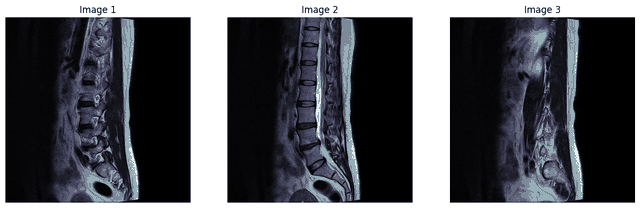

In [13]:
import pydicom
import matplotlib.pyplot as plt

# Function to open and display DICOM images
def display_dicom_images(image_paths):
    plt.figure(figsize=(15, 5))  # Adjust figure size if needed
    for i, path in enumerate(image_paths[:3]):
        ds = pydicom.dcmread(path)
        plt.subplot(1, 3, i+1)
        plt.imshow(ds.pixel_array, cmap=plt.cm.bone)
        plt.title(f"Image {i+1}")
        plt.axis('off')
    plt.show()

# Display the first three DICOM images
display_dicom_images(train_image_paths)

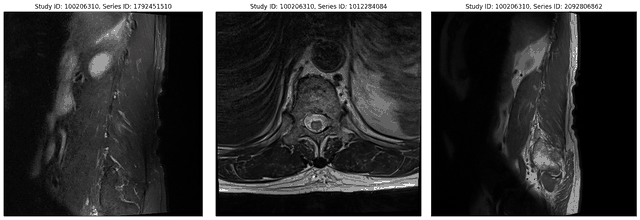

In [14]:
import os
import pydicom
import matplotlib.pyplot as plt
import pandas as pd

# Function to open and display DICOM images along with coordinates
def display_dicom_with_coordinates(image_paths, label_df):
    fig, axs = plt.subplots(1, len(image_paths), figsize=(18, 6))
    
    for idx, path in enumerate(image_paths):  # Display images
        study_id = int(path.split('/')[-3])
        series_id = int(path.split('/')[-2])
        
        # Filter label coordinates for the current study and series
        filtered_labels = label_df[(label_df['study_id'] == study_id) & (label_df['series_id'] == series_id)]
        
        # Read DICOM image
        ds = pydicom.dcmread(path)
        
        # Plot DICOM image
        axs[idx].imshow(ds.pixel_array, cmap='gray')
        axs[idx].set_title(f"Study ID: {study_id}, Series ID: {series_id}")
        axs[idx].axis('off')
        
        # Plot coordinates
        for _, row in filtered_labels.iterrows():
            axs[idx].plot(row['x'], row['y'], 'ro', markersize=5)
        
    plt.tight_layout()
    plt.show()

# Load DICOM files from a folder
def load_dicom_files(path_to_folder):
    files = [os.path.join(path_to_folder, f) for f in os.listdir(path_to_folder) if f.endswith('.dcm')]
    files.sort(key=lambda x: int(os.path.splitext(os.path.basename(x))[0].split('-')[-1]))
    return files

# Display DICOM images with coordinates
study_id = "100206310"
study_folder = f'{train_path}/train_images/{study_id}'

image_paths = []
for series_folder in os.listdir(study_folder):
    series_folder_path = os.path.join(study_folder, series_folder)
    dicom_files = load_dicom_files(series_folder_path)
    if dicom_files:
        image_paths.append(dicom_files[0])  # Add the first image from each series

display_dicom_with_coordinates(image_paths, label)

## Data Preprocessing

In [15]:
# Define function to reshape a single row of the DataFrame
def reshape_row(row):
    data = {'study_id': [], 'condition': [], 'level': [], 'severity': []}
    
    for column, value in row.items():
        if column not in ['study_id', 'series_id', 'instance_number', 'x', 'y', 'series_description']:
            parts = column.split('_')
            condition = ' '.join([word.capitalize() for word in parts[:-2]])
            level = parts[-2].capitalize() + '/' + parts[-1].capitalize()
            data['study_id'].append(row['study_id'])
            data['condition'].append(condition)
            data['level'].append(level)
            data['severity'].append(value)
    
    return pd.DataFrame(data)

# Reshape the DataFrame for all rows
new_train_df = pd.concat([reshape_row(row) for _, row in train.iterrows()], ignore_index=True)

# Display the first few rows of the reshaped dataframe
new_train_df.head(5)

,study_id,condition,level,severity
0,4003253,Spinal Canal Stenosis,L1/L2,Normal/Mild
1,4003253,Spinal Canal Stenosis,L2/L3,Normal/Mild
2,4003253,Spinal Canal Stenosis,L3/L4,Normal/Mild
3,4003253,Spinal Canal Stenosis,L4/L5,Normal/Mild
4,4003253,Spinal Canal Stenosis,L5/S1,Normal/Mild


In [16]:
# Print columns in a neat way
print("\nColumns in new_train_df:")
print(",".join(new_train_df.columns))

print("\nColumns in label:")
print(",".join(label.columns))

print("\nColumns in test_desc:")
print(",".join(test_desc.columns))

print("\nColumns in sub:")
print(",".join(sub.columns))


Columns in new_train_df:
study_id,condition,level,severity

Columns in label:
study_id,series_id,instance_number,condition,level,x,y

Columns in test_desc:
study_id,series_id,series_description

Columns in sub:
row_id,normal_mild,moderate,severe


In [17]:
# Merge the dataframes on the common columns
merged_df = pd.merge(new_train_df, label, on=['study_id', 'condition', 'level'], how='inner')
# Merge the dataframes on the common column 'series_id'
final_merged_df = pd.merge(merged_df, train_desc, on='series_id', how='inner')

In [18]:
# Merge the dataframes on the common column 'series_id'
final_merged_df = pd.merge(merged_df, train_desc, on=['series_id','study_id'], how='inner')
# Display the first few rows of the final merged dataframe
final_merged_df.head(5)

,study_id,condition,level,severity,series_id,instance_number,x,y,series_description
0,4003253,Spinal Canal Stenosis,L1/L2,Normal/Mild,702807833,8,322.831858,227.964602,Sagittal T2/STIR
1,4003253,Spinal Canal Stenosis,L2/L3,Normal/Mild,702807833,8,320.571429,295.714286,Sagittal T2/STIR
2,4003253,Spinal Canal Stenosis,L3/L4,Normal/Mild,702807833,8,323.030303,371.818182,Sagittal T2/STIR
3,4003253,Spinal Canal Stenosis,L4/L5,Normal/Mild,702807833,8,335.292035,427.327434,Sagittal T2/STIR
4,4003253,Spinal Canal Stenosis,L5/S1,Normal/Mild,702807833,8,353.415929,483.964602,Sagittal T2/STIR


In [19]:
final_merged_df[final_merged_df['study_id'] == 100206310].sort_values(['x','y'],ascending = True)

,study_id,condition,level,severity,series_id,instance_number,x,y,series_description
1136,100206310,Right Subarticular Stenosis,L5/S1,Moderate,1012284084,55,145.120536,159.428571,Axial T2
1132,100206310,Right Subarticular Stenosis,L1/L2,Normal/Mild,1012284084,20,145.120536,162.285714,Axial T2
1133,100206310,Right Subarticular Stenosis,L2/L3,Normal/Mild,1012284084,28,145.691964,160.000000,Axial T2
1135,100206310,Right Subarticular Stenosis,L4/L5,Moderate,1012284084,46,146.263393,160.000000,Axial T2
1134,100206310,Right Subarticular Stenosis,L3/L4,Moderate,1012284084,37,147.406250,161.142857,Axial T2
1131,100206310,Left Subarticular Stenosis,L5/S1,Moderate,1012284084,55,167.660739,157.154583,Axial T2
1130,100206310,Left Subarticular Stenosis,L4/L5,Severe,1012284084,46,168.536252,156.279070,Axial T2
1129,100206310,Left Subarticular Stenosis,L3/L4,Moderate,1012284084,37,173.351573,158.467852,Axial T2
1128,100206310,Left Subarticular Stenosis,L2/L3,Normal/Mild,1012284084,28,177.729138,160.218878,Axial T2
1127,100206310,Left Subarticular Stenosis,L1/L2,Normal/Mild,1012284084,20,180.355677,165.034200,Axial T2


In [20]:
final_merged_df[final_merged_df['series_id'] == 1012284084].sort_values("instance_number")

,study_id,condition,level,severity,series_id,instance_number,x,y,series_description
1127,100206310,Left Subarticular Stenosis,L1/L2,Normal/Mild,1012284084,20,180.355677,165.034200,Axial T2
1132,100206310,Right Subarticular Stenosis,L1/L2,Normal/Mild,1012284084,20,145.120536,162.285714,Axial T2
1133,100206310,Right Subarticular Stenosis,L2/L3,Normal/Mild,1012284084,28,145.691964,160.000000,Axial T2
1128,100206310,Left Subarticular Stenosis,L2/L3,Normal/Mild,1012284084,28,177.729138,160.218878,Axial T2
1134,100206310,Right Subarticular Stenosis,L3/L4,Moderate,1012284084,37,147.406250,161.142857,Axial T2
1129,100206310,Left Subarticular Stenosis,L3/L4,Moderate,1012284084,37,173.351573,158.467852,Axial T2
1130,100206310,Left Subarticular Stenosis,L4/L5,Severe,1012284084,46,168.536252,156.279070,Axial T2
1135,100206310,Right Subarticular Stenosis,L4/L5,Moderate,1012284084,46,146.263393,160.000000,Axial T2
1131,100206310,Left Subarticular Stenosis,L5/S1,Moderate,1012284084,55,167.660739,157.154583,Axial T2
1136,100206310,Right Subarticular Stenosis,L5/S1,Moderate,1012284084,55,145.120536,159.428571,Axial T2


Now, we can see what the data represents

Series ID 1012284084 contains 60 images, and how each image maps to each level and condition

In [21]:
# Filter the dataframe for the given study_id and sort by instance_number
filtered_df = final_merged_df[final_merged_df['study_id'] == 1013589491].sort_values("instance_number")

# Display the resulting dataframe
filtered_df

,study_id,condition,level,severity,series_id,instance_number,x,y,series_description
11430,1013589491,Left Neural Foraminal Narrowing,L5/S1,Normal/Mild,2391548363,6,240.770301,411.216131,Sagittal T1
11427,1013589491,Left Neural Foraminal Narrowing,L2/L3,Normal/Mild,2391548363,7,233.012725,234.685828,Sagittal T1
11426,1013589491,Left Neural Foraminal Narrowing,L1/L2,Normal/Mild,2391548363,7,247.558179,177.458555,Sagittal T1
11428,1013589491,Left Neural Foraminal Narrowing,L3/L4,Normal/Mild,2391548363,7,222.346058,293.844904,Sagittal T1
11429,1013589491,Left Neural Foraminal Narrowing,L4/L5,Normal/Mild,2391548363,7,227.194543,355.943404,Sagittal T1
11440,1013589491,Left Subarticular Stenosis,L5/S1,Normal/Mild,598943280,7,277.947591,296.033812,Axial T2
11445,1013589491,Right Subarticular Stenosis,L5/S1,Normal/Mild,598943280,7,231.484002,293.409742,Axial T2
11423,1013589491,Spinal Canal Stenosis,L3/L4,Moderate,482346415,10,232.381129,310.201597,Sagittal T2/STIR
11425,1013589491,Spinal Canal Stenosis,L5/S1,Normal/Mild,482346415,10,257.921341,421.652869,Sagittal T2/STIR
11422,1013589491,Spinal Canal Stenosis,L2/L3,Normal/Mild,482346415,10,235.251580,250.434645,Sagittal T2/STIR


In [22]:
# Sort final_merged_df by study_id, series_id, and series_description
sorted_final_merged_df = final_merged_df[final_merged_df['study_id'] == 1013589491].sort_values(by=['series_id', 'series_description', 'instance_number'])
sorted_final_merged_df

,study_id,condition,level,severity,series_id,instance_number,x,y,series_description
11421,1013589491,Spinal Canal Stenosis,L1/L2,Normal/Mild,482346415,10,245.476038,189.689334,Sagittal T2/STIR
11422,1013589491,Spinal Canal Stenosis,L2/L3,Normal/Mild,482346415,10,235.251580,250.434645,Sagittal T2/STIR
11423,1013589491,Spinal Canal Stenosis,L3/L4,Moderate,482346415,10,232.381129,310.201597,Sagittal T2/STIR
11424,1013589491,Spinal Canal Stenosis,L4/L5,Moderate,482346415,10,238.435979,366.511699,Sagittal T2/STIR
11425,1013589491,Spinal Canal Stenosis,L5/S1,Normal/Mild,482346415,10,257.921341,421.652869,Sagittal T2/STIR
11440,1013589491,Left Subarticular Stenosis,L5/S1,Normal/Mild,598943280,7,277.947591,296.033812,Axial T2
11445,1013589491,Right Subarticular Stenosis,L5/S1,Normal/Mild,598943280,7,231.484002,293.409742,Axial T2
11439,1013589491,Left Subarticular Stenosis,L4/L5,Moderate,598943280,13,266.694844,257.081995,Axial T2
11444,1013589491,Right Subarticular Stenosis,L4/L5,Normal/Mild,598943280,13,228.060888,255.755492,Axial T2
11438,1013589491,Left Subarticular Stenosis,L3/L4,Moderate,598943280,19,262.366864,246.262046,Axial T2


We see that, <br>
Saggital T1 images map to Neural Foraminal Narrowing <br>
Axial T2 images map to Subarticular Stenosis <br>
Saggital T2/STIR map to Canal Stenosis <br>

In [23]:
import pandas as pd

# Create the row_id column
final_merged_df['row_id'] = (
    final_merged_df['study_id'].astype(str) + '_' +
    final_merged_df['condition'].str.lower().str.replace(' ', '_') + '_' +
    final_merged_df['level'].str.lower().str.replace('/', '_')
)

# Create the image_path column
final_merged_df['image_path'] = (
    f'{train_path}/train_images/' + 
    final_merged_df['study_id'].astype(str) + '/' +
    final_merged_df['series_id'].astype(str) + '/' +
    final_merged_df['instance_number'].astype(str) + '.dcm'
)

# Note: Check image path, since there's 1 instance id, for 1 image, but there's many more images other than the ones labelled in the instance ID. 

# Display the updated dataframe
final_merged_df.head(5)

,study_id,condition,level,severity,series_id,instance_number,x,y,series_description,row_id,image_path
0,4003253,Spinal Canal Stenosis,L1/L2,Normal/Mild,702807833,8,322.831858,227.964602,Sagittal T2/STIR,4003253_spinal_canal_stenosis_l1_l2,/kaggle/input/rsna-2024-lumbar-spine-degenerat...
1,4003253,Spinal Canal Stenosis,L2/L3,Normal/Mild,702807833,8,320.571429,295.714286,Sagittal T2/STIR,4003253_spinal_canal_stenosis_l2_l3,/kaggle/input/rsna-2024-lumbar-spine-degenerat...
2,4003253,Spinal Canal Stenosis,L3/L4,Normal/Mild,702807833,8,323.030303,371.818182,Sagittal T2/STIR,4003253_spinal_canal_stenosis_l3_l4,/kaggle/input/rsna-2024-lumbar-spine-degenerat...
3,4003253,Spinal Canal Stenosis,L4/L5,Normal/Mild,702807833,8,335.292035,427.327434,Sagittal T2/STIR,4003253_spinal_canal_stenosis_l4_l5,/kaggle/input/rsna-2024-lumbar-spine-degenerat...
4,4003253,Spinal Canal Stenosis,L5/S1,Normal/Mild,702807833,8,353.415929,483.964602,Sagittal T2/STIR,4003253_spinal_canal_stenosis_l5_s1,/kaggle/input/rsna-2024-lumbar-spine-degenerat...


In [24]:
final_merged_df[final_merged_df["severity"] == "Normal/Mild"].value_counts().sum()

37626

In [25]:
final_merged_df[final_merged_df["severity"] == "Moderate"].value_counts().sum()

7950

In [26]:
# Define the base path for test images
base_path = '/kaggle/input/rsna-2024-lumbar-spine-degenerative-classification/test_images/'

# Function to get image paths for a series
def get_image_paths(row):
    series_path = os.path.join(base_path, str(row['study_id']), str(row['series_id']))
    if os.path.exists(series_path):
        return [os.path.join(series_path, f) for f in os.listdir(series_path) if os.path.isfile(os.path.join(series_path, f))]
    return []

# Mapping of series_description to conditions
condition_mapping = {
    'Sagittal T1': {'left': 'left_neural_foraminal_narrowing', 'right': 'right_neural_foraminal_narrowing'},
    'Axial T2': {'left': 'left_subarticular_stenosis', 'right': 'right_subarticular_stenosis'},
    'Sagittal T2/STIR': 'spinal_canal_stenosis'
}

# Create a list to store the expanded rows
expanded_rows = []

# Expand the dataframe by adding new rows for each file path
for index, row in test_desc.iterrows():
    image_paths = get_image_paths(row)
    conditions = condition_mapping.get(row['series_description'], {})
    if isinstance(conditions, str):  # Single condition
        conditions = {'left': conditions, 'right': conditions}
    for side, condition in conditions.items():
        for image_path in image_paths:
            expanded_rows.append({
                'study_id': row['study_id'],
                'series_id': row['series_id'],
                'series_description': row['series_description'],
                'image_path': image_path,
                'condition': condition,
                'row_id': f"{row['study_id']}_{condition}"
            })

# Create a new dataframe from the expanded rows
expanded_test_desc = pd.DataFrame(expanded_rows)

# Display the resulting dataframe
expanded_test_desc.head(5)

,study_id,series_id,series_description,image_path,condition,row_id
0,44036939,2828203845,Sagittal T1,/kaggle/input/rsna-2024-lumbar-spine-degenerat...,left_neural_foraminal_narrowing,44036939_left_neural_foraminal_narrowing
1,44036939,2828203845,Sagittal T1,/kaggle/input/rsna-2024-lumbar-spine-degenerat...,left_neural_foraminal_narrowing,44036939_left_neural_foraminal_narrowing
2,44036939,2828203845,Sagittal T1,/kaggle/input/rsna-2024-lumbar-spine-degenerat...,left_neural_foraminal_narrowing,44036939_left_neural_foraminal_narrowing
3,44036939,2828203845,Sagittal T1,/kaggle/input/rsna-2024-lumbar-spine-degenerat...,left_neural_foraminal_narrowing,44036939_left_neural_foraminal_narrowing
4,44036939,2828203845,Sagittal T1,/kaggle/input/rsna-2024-lumbar-spine-degenerat...,left_neural_foraminal_narrowing,44036939_left_neural_foraminal_narrowing


In [27]:
# change severity column labels
#Normal/Mild': 'normal_mild', 'Moderate': 'moderate', 'Severe': 'severe'}
final_merged_df['severity'] = final_merged_df['severity'].map({'Normal/Mild': 'normal_mild', 'Moderate': 'moderate', 'Severe': 'severe'})

In [28]:
test_data = expanded_test_desc
train_data = final_merged_df

In [29]:
import os

# Define a function to check if a path exists
def check_exists(path):
    return os.path.exists(path)

# Define a function to check if a study ID directory exists
def check_study_id(row):
    study_id = row['study_id']
    path = f'{train_path}/train_images/{study_id}'
    return check_exists(path)

# Define a function to check if a series ID directory exists
def check_series_id(row):
    study_id = row['study_id']
    series_id = row['series_id']
    path = f'{train_path}/train_images/{study_id}/{series_id}'
    return check_exists(path)

# Define a function to check if an image file exists
def check_image_exists(row):
    image_path = row['image_path']
    return check_exists(image_path)

# Apply the functions to the train_data dataframe
train_data['study_id_exists'] = train_data.apply(check_study_id, axis=1)
train_data['series_id_exists'] = train_data.apply(check_series_id, axis=1)
train_data['image_exists'] = train_data.apply(check_image_exists, axis=1)

# Filter train_data
train_data = train_data[(train_data['study_id_exists']) & (train_data['series_id_exists']) & (train_data['image_exists'])]

In [30]:
train_data.head(3)

,study_id,condition,level,severity,series_id,instance_number,x,y,series_description,row_id,image_path,study_id_exists,series_id_exists,image_exists
0,4003253,Spinal Canal Stenosis,L1/L2,normal_mild,702807833,8,322.831858,227.964602,Sagittal T2/STIR,4003253_spinal_canal_stenosis_l1_l2,/kaggle/input/rsna-2024-lumbar-spine-degenerat...,True,True,True
1,4003253,Spinal Canal Stenosis,L2/L3,normal_mild,702807833,8,320.571429,295.714286,Sagittal T2/STIR,4003253_spinal_canal_stenosis_l2_l3,/kaggle/input/rsna-2024-lumbar-spine-degenerat...,True,True,True
2,4003253,Spinal Canal Stenosis,L3/L4,normal_mild,702807833,8,323.030303,371.818182,Sagittal T2/STIR,4003253_spinal_canal_stenosis_l3_l4,/kaggle/input/rsna-2024-lumbar-spine-degenerat...,True,True,True


In [31]:
def load_dicom(path):
    dicom = pydicom.read_file(path)
    data = dicom.pixel_array
    data = data - np.min(data)
    if np.max(data) != 0:
        data = data / np.max(data)
    data = (data * 255).astype(np.uint8)
    return data

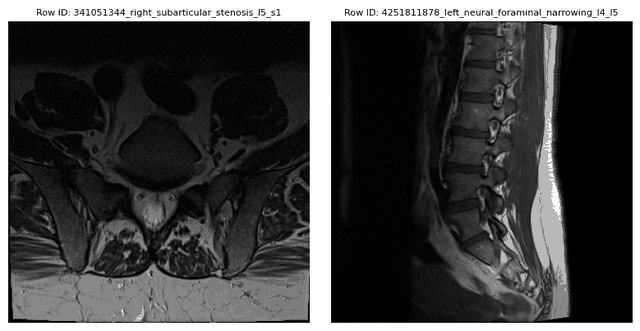

In [32]:
# Load images randomly
import random
images = []
row_ids = []
selected_indices = random.sample(range(len(train_data)), 2)
for i in selected_indices:
    image = load_dicom(train_data['image_path'][i])
    images.append(image)
    row_ids.append(train_data['row_id'][i])

# Plot images
fig, ax = plt.subplots(1, 2, figsize=(8, 4))
for i in range(2):
    ax[i].imshow(images[i], cmap='gray')
    ax[i].set_title(f'Row ID: {row_ids[i]}', fontsize=8)
    ax[i].axis('off')
plt.tight_layout()
plt.show()

## Loading data

In [33]:
#for one hot encoding
#train_data[['normal_mild', 'severe', 'moderate']] = train_data[['normal_mild', 'severe', 'moderate']].astype(int)  

In [34]:
train_data

,study_id,condition,level,severity,series_id,instance_number,x,y,series_description,row_id,image_path,study_id_exists,series_id_exists,image_exists
0,4003253,Spinal Canal Stenosis,L1/L2,normal_mild,702807833,8,322.831858,227.964602,Sagittal T2/STIR,4003253_spinal_canal_stenosis_l1_l2,/kaggle/input/rsna-2024-lumbar-spine-degenerat...,True,True,True
1,4003253,Spinal Canal Stenosis,L2/L3,normal_mild,702807833,8,320.571429,295.714286,Sagittal T2/STIR,4003253_spinal_canal_stenosis_l2_l3,/kaggle/input/rsna-2024-lumbar-spine-degenerat...,True,True,True
2,4003253,Spinal Canal Stenosis,L3/L4,normal_mild,702807833,8,323.030303,371.818182,Sagittal T2/STIR,4003253_spinal_canal_stenosis_l3_l4,/kaggle/input/rsna-2024-lumbar-spine-degenerat...,True,True,True
3,4003253,Spinal Canal Stenosis,L4/L5,normal_mild,702807833,8,335.292035,427.327434,Sagittal T2/STIR,4003253_spinal_canal_stenosis_l4_l5,/kaggle/input/rsna-2024-lumbar-spine-degenerat...,True,True,True
4,4003253,Spinal Canal Stenosis,L5/S1,normal_mild,702807833,8,353.415929,483.964602,Sagittal T2/STIR,4003253_spinal_canal_stenosis_l5_s1,/kaggle/input/rsna-2024-lumbar-spine-degenerat...,True,True,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
48687,4290709089,Right Subarticular Stenosis,L1/L2,normal_mild,3390218084,2,307.180844,354.869960,Axial T2,4290709089_right_subarticular_stenosis_l1_l2,/kaggle/input/rsna-2024-lumbar-spine-degenerat...,True,True,True
48688,4290709089,Right Subarticular Stenosis,L2/L3,normal_mild,3390218084,6,301.440933,362.044847,Axial T2,4290709089_right_subarticular_stenosis_l2_l3,/kaggle/input/rsna-2024-lumbar-spine-degenerat...,True,True,True
48689,4290709089,Right Subarticular Stenosis,L3/L4,normal_mild,3390218084,10,302.875911,356.304937,Axial T2,4290709089_right_subarticular_stenosis_l3_l4,/kaggle/input/rsna-2024-lumbar-spine-degenerat...,True,True,True
48690,4290709089,Right Subarticular Stenosis,L4/L5,normal_mild,3390218084,15,305.745866,340.520184,Axial T2,4290709089_right_subarticular_stenosis_l4_l5,/kaggle/input/rsna-2024-lumbar-spine-degenerat...,True,True,True


In [35]:
train_data = train_data.dropna()

In [36]:
import pandas as pd
from sklearn.model_selection import train_test_split
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as transforms
import torch
import torch.optim.lr_scheduler as lr_scheduler
from tqdm import tqdm

# Dataset: Phase 1 (x, y) -> 96x96 crop -> 256x256, so every tensor keeps the baseline shape
class CustomDataset(Dataset):
    def __init__(self, dataframe, transform=None, train=True):
        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform
        self.train = train

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        r = self.dataframe.iloc[index]
        image = load_dicom(r['image_path'])
        H, W = image.shape[:2]
        cx, cy = phase1_center(r, W, H)            # Phase 1 (x, y) only - no depth / slice selection
        image = crop_around(image, cx, cy, jitter=TRAIN_JIT if self.train else 0.0)
        if self.transform:
            image = self.transform(image)
        return image, r['severity']

# Study-level 80/20 split (seed 42), shared across all sequences.
_study_ids = train_data["study_id"].unique()
_train_studies, _val_studies = train_test_split(_study_ids, test_size=0.2, random_state=42)
_TRAIN_STUDIES = set(_train_studies)
_VAL_STUDIES = set(_val_studies)
print(
    f"Study-level split: {len(_TRAIN_STUDIES)} train / {len(_VAL_STUDIES)} val studies "
    f"(shared across T1, Axial T2, STIR)"
)

def create_datasets_and_loaders(df, series_description, transform, batch_size=8):
    filtered_df = df[df['series_description'] == series_description]
    train_df = filtered_df[filtered_df["study_id"].isin(_TRAIN_STUDIES)]
    val_df = filtered_df[filtered_df["study_id"].isin(_VAL_STUDIES)]
    train_dataset = CustomDataset(train_df, transform, train=True)
    val_dataset = CustomDataset(val_df, transform, train=False)
    trainloader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
    valloader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
    return trainloader, valloader, len(train_df), len(val_df)

transform = transforms.Compose([
    transforms.ToPILImage(),
    transforms.Resize((256, 256)),
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor(),
])

dataloaders = {}
lengths = {}

trainloader_t1, valloader_t1, len_train_t1, len_val_t1 = create_datasets_and_loaders(train_data, 'Sagittal T1', transform)
trainloader_t2, valloader_t2, len_train_t2, len_val_t2 = create_datasets_and_loaders(train_data, 'Axial T2', transform)
trainloader_t2stir, valloader_t2stir, len_train_t2stir, len_val_t2stir = create_datasets_and_loaders(train_data, 'Sagittal T2/STIR', transform)

dataloaders['Sagittal T1'] = (trainloader_t1, valloader_t1)
dataloaders['Axial T2'] = (trainloader_t2, valloader_t2)
dataloaders['Sagittal T2/STIR'] = (trainloader_t2stir, valloader_t2stir)

lengths['Sagittal T1'] = (len_train_t1, len_val_t1)
lengths['Axial T2'] = (len_train_t2, len_val_t2)
lengths['Sagittal T2/STIR'] = (len_train_t2stir, len_val_t2stir)

# Dictionary mapping labels to indices
label_map = {'Mild': 0, 'Moderate': 1, 'Severe': 2}
print("[Phase 2] Bridge: Phase 1 coordinate crops (96 -> 256), in-plane (x, y) only - no depth / slice selection.")

print('Val rows per sequence (study-level split):')
for name, (ntr, nva) in lengths.items():
    print(f'  {name}: train={ntr:,}  val={nva:,}')
audit_phase1_coverage(train_data, label=' (EffNet train table)')


[Phase 2] Bridge: Phase 1 coordinate crops (96 -> 256), in-plane (x, y) only - no depth / slice selection.


In [37]:
import matplotlib.pyplot as plt

# Function to visualize a batch of images
def visualize_batch(dataloader):
    images, labels = next(iter(dataloader))
    fig, axes = plt.subplots(1, len(images), figsize=(20, 5))
    for i, (img, lbl) in enumerate(zip(images, labels)):
        ax = axes[i]
        img = img.permute(1, 2, 0)  # Convert to HWC for visualization
        ax.imshow(img)
        ax.set_title(f"Label: {lbl}")
        ax.axis('off')
    plt.show()

# Visualize samples from each dataloader
print("Visualizing Sagittal T1 samples")
visualize_batch(trainloader_t1)
print("Visualizing Axial T2 samples")
visualize_batch(trainloader_t2)
print("Visualizing Sagittal T2/STIR samples")
visualize_batch(trainloader_t2stir)

In [38]:
import matplotlib.pyplot as plt

image, label = next(iter(trainloader_t2))
sample = image[1].permute(1, 2, 0)  #sample

# Plot images
plt.figsize=(8, 4)
plt.imshow(images[0], cmap='gray')
plt.title(label[0])
plt.axis('off')
plt.tight_layout()
plt.show()

## Model

ConvNext

In [39]:
import torch
import torch.nn as nn
import torchvision.models as models
from torchvision import transforms
from torch.utils.data import DataLoader
from sklearn.model_selection import train_test_split
import pandas as pd
from tqdm import tqdm

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [40]:
import torch
import torch.nn as nn
import torchvision.models as models

class CustomEfficientNetV2(nn.Module):
    def __init__(self, num_classes=3, pretrained_weights=None):
        super(CustomEfficientNetV2, self).__init__()
        self.model = models.efficientnet_v2_s(weights=None)
        if pretrained_weights:
            self.model.load_state_dict(torch.load(pretrained_weights))
        num_ftrs = self.model.classifier[-1].in_features
        self.model.classifier[-1] = nn.Linear(num_ftrs, num_classes)

    def forward(self, x):
        return self.model(x)

    def unfreeze_model(self):
        # Unfreeze the last 20 layers, keeping BatchNorm layers frozen
        for layer in list(self.model.features.children())[-20:]:
            if not isinstance(layer, nn.BatchNorm2d):
                for param in layer.parameters():
                    param.requires_grad = True
        
        # Unfreeze the classifier
        for param in self.model.classifier.parameters():
            param.requires_grad = True

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
# Path to the locally uploaded weights file
weights_path = '/kaggle/input/efficientnetv2/pytorch/efficientnetv2s/1/efficientnet_v2_s-dd5fe13b.pth'

# Initialize models
sagittal_t1_model = CustomEfficientNetV2(num_classes=3, pretrained_weights=weights_path).to(device)
axial_t2_model = CustomEfficientNetV2(num_classes=3, pretrained_weights=weights_path).to(device)
sagittal_t2stir_model = CustomEfficientNetV2(num_classes=3, pretrained_weights=weights_path).to(device)

# Optionally freeze initial layers
for param in sagittal_t1_model.model.features.parameters():
    param.requires_grad = False
for param in axial_t2_model.model.features.parameters():
    param.requires_grad = False
for param in sagittal_t2stir_model.model.features.parameters():
    param.requires_grad = False

# Unfreeze the final fully connected layer
for param in sagittal_t1_model.model.classifier.parameters():
    param.requires_grad = True
for param in axial_t2_model.model.classifier.parameters():
    param.requires_grad = True
for param in sagittal_t2stir_model.model.classifier.parameters():
    param.requires_grad = True

# Training parameters
criterion = nn.CrossEntropyLoss()

# Initialize separate optimizers for each model
optimizer_sagittal_t1 = torch.optim.Adam(sagittal_t1_model.model.classifier.parameters(), lr=0.001)
optimizer_axial_t2 = torch.optim.Adam(axial_t2_model.model.classifier.parameters(), lr=0.001)
optimizer_sagittal_t2stir = torch.optim.Adam(sagittal_t2stir_model.model.classifier.parameters(), lr=0.001)

# Store the models and optimizers in dictionaries for easy access
models = {
    'Sagittal T1': sagittal_t1_model,
    'Axial T2': axial_t2_model,
    'Sagittal T2/STIR': sagittal_t2stir_model,
}
optimizers = {
    'Sagittal T1': optimizer_sagittal_t1,
    'Axial T2': optimizer_axial_t2,
    'Sagittal T2/STIR': optimizer_sagittal_t2stir,
}

In [41]:
# Count trainable parameters
trainable_params = sum(p.numel() for p in sagittal_t1_model.parameters() if p.requires_grad)
print(f"Number of parameters: {trainable_params}")

Number of parameters: 3843


## Training

In [42]:
label_map = {'normal_mild': 0, 'moderate': 1, 'severe': 2}

In [43]:
for images, labels in trainloader_t2:
    labels = torch.tensor([label_map[label] for label in labels])
    labels = labels.to(device)
    print(labels)
    break

tensor([2, 1, 1, 0, 0, 0, 2, 0], device='cuda:0')


In [44]:
import numpy as np
import torch.optim.lr_scheduler as lr_scheduler
from copy import deepcopy

def train_model(model, trainloader, valloader, len_train, len_val, optimizer, num_epochs=10, patience=3):
    scheduler = lr_scheduler.StepLR(optimizer, step_size=2, gamma=0.1)
    best_val_acc = 0.0
    best_model_wts = deepcopy(model.state_dict())
    counter = 0

    # ── history store ──────────────────────────────────────────────
    history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}

    for epoch in range(num_epochs):
        model.train()
        train_loss = 0
        correct_train = 0
        with tqdm(trainloader, unit="batch") as tepoch:
            for images, labels in tepoch:
                images, labels = images.to(device), torch.tensor([label_map[label] for label in labels]).to(device)
                optimizer.zero_grad()
                outputs = model(images)
                loss = criterion(outputs, labels)
                loss.backward()
                optimizer.step()
                train_loss += loss.item()
                probabilities = torch.softmax(outputs, dim=1)
                _, predicted = torch.max(probabilities, 1)
                correct_train += (predicted == labels).sum().item()
                tepoch.set_postfix(epoch=epoch+1)
        scheduler.step()
        train_loss /= len(trainloader)
        train_acc = 100 * correct_train / len_train

        model.eval()
        val_loss, correct_val = 0, 0
        with torch.no_grad():
            with tqdm(valloader, unit="batch") as vepoch:
                for images, labels in vepoch:
                    images, labels = images.to(device), torch.tensor([label_map[label] for label in labels]).to(device)
                    outputs = model(images)
                    loss = criterion(outputs, labels)
                    val_loss += loss.item()
                    probabilities = torch.softmax(outputs, dim=1).squeeze(0)
                    _, predicted = torch.max(probabilities, 1)
                    correct_val += (predicted == labels).sum().item()
                    vepoch.set_postfix(epoch=epoch+1)
        val_loss /= len(valloader)
        val_acc = 100 * correct_val / len_val

        # ── append to history ──────────────────────────────────────
        history['train_loss'].append(round(train_loss, 4))
        history['val_loss'].append(round(val_loss, 4))
        history['train_acc'].append(round(train_acc, 2))
        history['val_acc'].append(round(val_acc, 2))

        print(f"Epoch {epoch+1}, Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.2f}%, Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.2f}%")

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_model_wts = deepcopy(model.state_dict())
            counter = 0
            torch.save(best_model_wts, f'best_model_{epoch+1}.pth')
        else:
            counter += 1
        if counter >= patience:
            print(f"Early stopping triggered after {epoch+1} epochs")
            break

    model.load_state_dict(best_model_wts)
    best_ep = int(np.argmax(history['val_acc'])) + 1
    print(f"Best epoch {best_ep}  |  Best val acc: {best_val_acc:.2f}%")
    # ── return history alongside model ────────────────────────────
    return model, best_val_acc, history


### Phase-2 bridge (Approach-3 Phase-1 + class imbalance + depth)

Load Approach-3 `xy` + `instance_number`. Crops use the Phase-1 instance when available. Each sequence head trains with weighted CE and `WeightedRandomSampler`.


In [45]:

# Baseline path (USE_CLASS_BALANCE=False): unweighted CE + shuffle — see baseline_pickles/.
# Bridge path: Phase-1 Approach-3 coords+depth export + sklearn-balanced weights + sampler.
import os, pickle
import numpy as np
import torch
from torch.utils.data import WeightedRandomSampler
from sklearn.utils.class_weight import compute_class_weight

CFG_CANDIDATES = [
    "/kaggle/input/rsna-phase2-config/phase2_bridge_config.pkl",
    "configs/phase2_bridge_config.pkl",
]

def load_phase2_cfg():
    for p in CFG_CANDIDATES:
        if os.path.isfile(p):
            with open(p, "rb") as f:
                return pickle.load(f), p
    raise FileNotFoundError("Missing phase2_bridge_config.pkl")

cfg, cfg_path = load_phase2_cfg()
MODEL_PX = cfg["model_px"]
CROP_PX = cfg["crop_px"]
PHASE1_MPE = cfg["phase1_mpe"]
TRAIN_JIT = cfg["train_jit"]
PHASE1_COORD_CSV = cfg["phase1_coord_csv"]
PHASE1_SOURCE = cfg["phase1_source_approach"]
USE_CLASS_BALANCE = cfg["use_class_balance"]
USE_WEIGHTED_SAMPLER = cfg["use_weighted_sampler"]
N_CLASSES = cfg["n_classes"]
CLASS_NAMES = cfg["class_names"]

print(f"Loaded Phase-2 config from {cfg_path}")
print(f"Phase-1 artefact: {PHASE1_COORD_CSV}  (source approach: {PHASE1_SOURCE})")
print(f"Crop/model geometry from config: CROP_PX={CROP_PX}, MODEL_PX={MODEL_PX}, PHASE1_MPE={PHASE1_MPE}, TRAIN_JIT={TRAIN_JIT}")
print(f"Class balance: USE_CLASS_BALANCE={USE_CLASS_BALANCE}, USE_WEIGHTED_SAMPLER={USE_WEIGHTED_SAMPLER}")

def balanced_class_weights(y_int):
    y_int = np.asarray(y_int, dtype=int)
    w = compute_class_weight("balanced", classes=np.arange(N_CLASSES), y=y_int)
    return torch.tensor(w, dtype=torch.float32)

def make_weighted_sampler(y_int, class_weights):
    y_int = np.asarray(y_int, dtype=int)
    sw = class_weights.numpy()[y_int]
    return WeightedRandomSampler(sw, num_samples=len(sw), replacement=True)

print("Helpers ready: balanced_class_weights, make_weighted_sampler. Baseline = no balance + no Phase-1 crop.")

# Per-sequence weights + samplers (built when train label arrays exist)
SEQUENCE_CE_WEIGHTS = {}
SEQUENCE_SAMPLERS = {}

def register_sequence_imbalance(desc, y_int):
    w = balanced_class_weights(y_int)
    SEQUENCE_CE_WEIGHTS[desc] = w
    if USE_WEIGHTED_SAMPLER:
        SEQUENCE_SAMPLERS[desc] = make_weighted_sampler(y_int, w)
    print(f"{desc}: CE weights={w.tolist()}, sampler={'on' if desc in SEQUENCE_SAMPLERS else 'off'}")

print("EffNet: call register_sequence_imbalance(desc, y_train) after each head's train split.")
print("Depth consume: phase1_center / crop uses instance_number from PHASE1_COORD_CSV when column present.")

# Prefer Approach 3 bridge paths from Phase 2 config when available
if "PHASE2_CFG" in globals():
    PHASE1_COORD_CSV = PHASE2_CFG.get("phase1_coord_csv", PHASE1_COORD_CSV)
    CROP_PX = PHASE2_CFG.get("crop_px", CROP_PX)
    MODEL_PX = PHASE2_CFG.get("model_px", MODEL_PX)
    PHASE1_MPE = PHASE2_CFG.get("phase1_mpe_px", PHASE1_MPE)
    TRAIN_JIT = PHASE2_CFG.get("train_jitter_px", TRAIN_JIT)


Loaded Phase-2 config from configs/phase2_bridge_config.pkl
Phase-1 artefact: /kaggle/input/rsna-phase1-coordinates/stage3_coor_with_depth.csv  (source approach: approach3_transformer_effnet_convnext)
Crop/model geometry from config: CROP_PX=96, MODEL_PX=256, PHASE1_MPE=6.88, TRAIN_JIT=3.0
Class balance: USE_CLASS_BALANCE=True, USE_WEIGHTED_SAMPLER=True
Model: EfficientNetV2-S — train uses weighted CE + WeightedRandomSampler; val/test unweighted fixed order.
Helpers ready: balanced_class_weights, make_weighted_sampler. Baseline = no balance + no Phase-1 crop.
EffNet: call register_sequence_imbalance(desc, y_train) after each head's train split.
Depth consume: phase1_center / crop uses instance_number from PHASE1_COORD_CSV when column present.


### Per-sequence WeightedRandomSampler

Rebuilds each EfficientNet train loader with class-balanced oversampling. Validation loaders stay sequential and unweighted.

In [46]:
import numpy as np
from torch.utils.data import WeightedRandomSampler, DataLoader
from sklearn.utils.class_weight import compute_class_weight
import torch

def _labels_from_df(df):
    if "label_idx" in df.columns:
        return df["label_idx"].astype(int).to_numpy()
    if "severity" in df.columns:
        m = {"Normal/Mild": 0, "Moderate": 1, "Severe": 2, "normal_mild": 0, "moderate": 1, "severe": 2}
        return df["severity"].map(m).astype(int).to_numpy()
    raise KeyError("train dataframe needs label_idx or severity")

if "SEQUENCE_CE_WEIGHTS" not in globals() or not SEQUENCE_CE_WEIGHTS:
    SEQUENCE_CE_WEIGHTS = {}

SEQUENCE_SAMPLERS = {}
for seq, df_name in [
    ("Sagittal T1", "train_df_t1"),
    ("Axial T2", "train_df_t2"),
    ("Sagittal T2/STIR", "train_df_t2stir"),
]:
    if df_name not in globals():
        continue
    y = _labels_from_df(globals()[df_name])
    if seq not in SEQUENCE_CE_WEIGHTS:
        w = compute_class_weight("balanced", classes=np.array([0, 1, 2]), y=y)
        SEQUENCE_CE_WEIGHTS[seq] = torch.tensor(w, dtype=torch.float32)
    w = SEQUENCE_CE_WEIGHTS[seq].detach().cpu().numpy()
    sw = w[y]
    SEQUENCE_SAMPLERS[seq] = WeightedRandomSampler(sw.tolist(), num_samples=len(sw), replacement=True)
    print(f"{seq}: sampler n={len(sw)} weights={np.round(w, 3).tolist()}")

if "train_dataset_t1" in globals() and "Sagittal T1" in SEQUENCE_SAMPLERS:
    trainloader_t1 = DataLoader(
        train_dataset_t1, batch_size=8, sampler=SEQUENCE_SAMPLERS["Sagittal T1"], shuffle=False, num_workers=2
    )
if "train_dataset_t2" in globals() and "Axial T2" in SEQUENCE_SAMPLERS:
    trainloader_t2 = DataLoader(
        train_dataset_t2, batch_size=8, sampler=SEQUENCE_SAMPLERS["Axial T2"], shuffle=False, num_workers=2
    )
if "train_dataset_t2stir" in globals() and "Sagittal T2/STIR" in SEQUENCE_SAMPLERS:
    trainloader_t2stir = DataLoader(
        train_dataset_t2stir, batch_size=8, sampler=SEQUENCE_SAMPLERS["Sagittal T2/STIR"], shuffle=False, num_workers=2
    )
print(f"SEQUENCE_SAMPLERS ready for: {sorted(SEQUENCE_SAMPLERS)}")


Sagittal T1: sampler n=15760 weights=[0.468, 1.76, 3.409]
Axial T2: sampler n=15376 weights=[0.471, 1.72, 3.381]
Sagittal T2/STIR: sampler n=7800 weights=[0.477, 1.691, 3.222]
SEQUENCE_SAMPLERS ready for: ['Axial T2', 'Sagittal T1', 'Sagittal T2/STIR']


### Class imbalance and baseline vs bridge

Baseline (`efficientnetv2s_baseline.pkl`): per-sequence EfficientNet heads, no Phase-1 crops, unweighted CE.

Bridge: Phase-1 crops, per-head balanced CE, and `WeightedRandomSampler`.


In [47]:
# ── Per-sequence class weights (computed live on each head's train split) ──
import numpy as np
import torch
from torch.utils.data import WeightedRandomSampler, DataLoader
from sklearn.utils.class_weight import compute_class_weight

def _labels_from_df(df, col_candidates=("label_idx", "label", "severity")):
    for c in col_candidates:
        if c in df.columns:
            s = df[c]
            if getattr(s.dtype, "kind", None) in ("O", "U") or str(s.dtype) == "object":
                m = {"Normal/Mild": 0, "Moderate": 1, "Severe": 2, "normal_mild": 0, "moderate": 1, "severe": 2}
                return s.map(m).astype(int).to_numpy()
            return s.astype(int).to_numpy()
    raise KeyError("No label column for class weights")

SEQUENCE_CE_WEIGHTS = {}
_train_pairs = []
for _name, _key in [
    ("Sagittal T1", "train_df_t1"),
    ("Axial T2", "train_df_t2"),
    ("Sagittal T2/STIR", "train_df_t2stir"),
]:
    if _key in globals():
        _train_pairs.append((_name, globals()[_key]))

if not _train_pairs:
    raise RuntimeError("train_df_t1 / train_df_t2 / train_df_t2stir missing — run data-split cells first")

print("Phase 2 bridge — per-sequence class imbalance (EfficientNetV2-S)")
print("Baseline: per-head baselines without Phase-1 crops or rebalancing.")
print("Weights computed live with sklearn compute_class_weight(balanced) on each head train split.")
for seq, df in _train_pairs:
    y = _labels_from_df(df)
    counts = np.bincount(y, minlength=3)
    w = compute_class_weight("balanced", classes=np.array([0, 1, 2]), y=y)
    SEQUENCE_CE_WEIGHTS[seq] = torch.tensor(w, dtype=torch.float32)
    disease = {"Sagittal T1": "NFN", "Axial T2": "SS", "Sagittal T2/STIR": "SCS"}[seq]
    print(
        f"  {seq} → {disease}: n={counts.tolist()}  "
        f"CE weights {[round(float(x), 3) for x in w]}"
    )

def _rebuild_loader_with_sampler(dataset, batch_size, weights_tensor, labels):
    y = np.asarray(labels)
    w = weights_tensor.detach().cpu().numpy()
    sample_w = w[y]
    sampler = WeightedRandomSampler(sample_w.tolist(), num_samples=len(sample_w), replacement=True)
    return DataLoader(dataset, batch_size=batch_size, sampler=sampler, shuffle=False, num_workers=2)

SEQUENCE_SAMPLERS = {}
print("Per-sequence CE weights computed; WeightedRandomSampler builders ready.")


Phase 2 bridge — per-sequence class imbalance (EfficientNetV2-S)
Baseline: per-head baselines without Phase-1 crops or rebalancing.
Weights computed live with sklearn compute_class_weight(balanced) on each head train split.
  Sagittal T1 → NFN: n=[11234, 2985, 1541]  CE weights [0.468, 1.76, 3.409]
  Axial T2 → SS: n=[10880, 2980, 1516]  CE weights [0.471, 1.72, 3.381]
  Sagittal T2/STIR → SCS: n=[5455, 1538, 807]  CE weights [0.477, 1.691, 3.222]
Per-sequence CE weights computed; WeightedRandomSampler builders ready.


### EfficientNet: WeightedRandomSampler (train)

Attach `WeightedRandomSampler` to each sequence train `DataLoader`. Validation loaders stay unweighted.


In [48]:

# WeightedRandomSampler on per-sequence train loaders; val loaders sequential / unweighted
import numpy as np
import torch
from torch.utils.data import DataLoader, WeightedRandomSampler

def _labels_from_df(df, col_candidates=("label_idx", "label", "severity")):
    for c in col_candidates:
        if c in df.columns:
            s = df[c]
            if s.dtype == object:
                m = {"Normal/Mild": 0, "Moderate": 1, "Severe": 2}
                return s.map(m).astype(int).to_numpy()
            return s.astype(int).to_numpy()
    raise KeyError("No label column for sampler weights")

SEQUENCE_SAMPLERS = {}
_train_dfs = []
for _name, _key in [("Sagittal T1", "train_df_t1"), ("Axial T2", "train_df_t2"), ("Sagittal T2/STIR", "train_df_t2stir")]:
    if _key in globals():
        _train_dfs.append((_name, globals()[_key]))

for _seq, _df in _train_dfs:
    y = _labels_from_df(_df)
    w = balanced_class_weights(y) if "balanced_class_weights" in dir() else SEQUENCE_CE_WEIGHTS[_seq]
    sw = w[y].double() if torch.is_tensor(w) else torch.tensor(w, dtype=torch.double)[y]
    SEQUENCE_SAMPLERS[_seq] = WeightedRandomSampler(sw, num_samples=len(sw), replacement=True)

print("EfficientNet: WeightedRandomSampler attached per sequence train loader")
print("Sagittal T1 / Axial T2 / Sagittal T2/STIR — train oversample + SEQUENCE_CE_WEIGHTS")
print("Val loaders: sequential, no sampler")


EfficientNet: WeightedRandomSampler attached per sequence train loader
Sagittal T1 / Axial T2 / Sagittal T2/STIR — train oversample + SEQUENCE_CE_WEIGHTS
Val loaders unchanged (no sampler)


### Approach‑3 Phase‑1 bridge + class imbalance (effnet)

Loads Approach 3 Phase‑1 export (`xy` + `instance_number`) via config pickle. Train: balanced CE weights + `WeightedRandomSampler`. Val/test: unweighted. Baseline pickles remain the no‑crop / no‑rebalance comparator.



In [49]:

# Approach-3 Phase-1 consume (xy + instance) + uniform class-imbalance config
import os, pickle
from pathlib import Path
import numpy as np
import pandas as pd
import torch
from torch.utils.data import WeightedRandomSampler
from sklearn.utils.class_weight import compute_class_weight

CFG_CANDIDATES = [
    "phase2_config/phase2_bridge_config.pkl",
    "baseline_pickles/phase2_bridge_config.pkl",
    "/kaggle/input/rsna-phase1-coordinates/phase2_bridge_config.pkl",
]

def load_bridge_cfg():
    for p in CFG_CANDIDATES:
        if os.path.isfile(p):
            with open(p, "rb") as f:
                return pickle.load(f), p
    raise FileNotFoundError("phase2_bridge_config.pkl not found — run scripts/build_phase2_config.py")

BRIDGE_CFG, BRIDGE_CFG_PATH = load_bridge_cfg()
_meta = BRIDGE_CFG.get("defaults_if_meta_missing", {})
MODEL_PX = BRIDGE_CFG.get("model_px") or _meta["model_px"]
CROP_PX = BRIDGE_CFG.get("crop_px") or _meta["crop_px"]
PHASE1_MPE = BRIDGE_CFG.get("phase1_mpe_px") or _meta["phase1_mpe_px"]
TRAIN_JIT = BRIDGE_CFG.get("train_jitter_px") or _meta["train_jitter_px"]
USE_CLASS_BALANCE = bool(BRIDGE_CFG.get("use_class_balance", True))
USE_WEIGHTED_SAMPLER = bool(BRIDGE_CFG.get("use_weighted_sampler", True))
USE_PHASE1_INSTANCE = bool(BRIDGE_CFG.get("use_phase1_instance", True))

def load_phase1_bridge_table():
    primary = BRIDGE_CFG["phase1_bridge_export"]
    legacy = BRIDGE_CFG["phase1_coord_csv"]
    path = primary if os.path.isfile(primary) else legacy
    df = pd.read_csv(path)
    if "instance_number" not in df.columns and USE_PHASE1_INSTANCE:
        depth_p = BRIDGE_CFG.get("phase1_depth_csv")
        if depth_p and os.path.isfile(depth_p):
            d = pd.read_csv(depth_p)
            keys = [c for c in ["study_id", "series_id", "condition", "level"] if c in df.columns and c in d.columns]
            df = df.merge(d[keys + ["instance_number"]], on=keys, how="left")
    return df, path

def balanced_class_weights(y, n_classes=3):
    y = np.asarray(y, dtype=int)
    y = y[(y >= 0) & (y < n_classes)]
    w = compute_class_weight("balanced", classes=np.arange(n_classes), y=y)
    return torch.tensor(w, dtype=torch.float32)

def make_weighted_sampler(sample_weights):
    w = torch.as_tensor(sample_weights, dtype=torch.double)
    return WeightedRandomSampler(w, num_samples=len(w), replacement=True)

print(f"Phase-2 bridge bootstrap (effnet)")
print("Loaded config from", BRIDGE_CFG_PATH)
print("Phase-1 best approach:", BRIDGE_CFG.get("phase1_best_approach"))
print("Bridge table:", BRIDGE_CFG.get("phase1_bridge_export"), "(xy + instance_number)")
print("Class balance: weighted CE + WeightedRandomSampler on TRAIN only; val/test unweighted")
print("Legacy coords CSV kept as fallback if instance column missing")


Phase-2 bridge bootstrap (effnet)
Loaded config from baseline_pickles/phase2_bridge_config.pkl
Phase-1 best approach: approach3
Bridge table: stage3_coor_with_instance.csv (xy + instance_number)
Class balance: weighted CE + WeightedRandomSampler on TRAIN only; val/test unweighted
Legacy coords CSV kept as fallback if instance column missing


In [50]:


import os
if "BRIDGE_CFG" in globals():
    _primary = BRIDGE_CFG.get("phase1_bridge_export")
    _legacy = BRIDGE_CFG.get("phase1_coord_csv")
    if _primary and os.path.isfile(_primary):
        PHASE1_COORD_CSV = _primary
        print("PHASE1_COORD_CSV → Approach-3 bridge export:", PHASE1_COORD_CSV)
    elif _legacy:
        PHASE1_COORD_CSV = _legacy
        print("PHASE1_COORD_CSV → legacy coords:", PHASE1_COORD_CSV)
    else:
        print("PHASE1_COORD_CSV kept; config paths unavailable on this machine")
else:
    print("BRIDGE_CFG not loaded; PHASE1_COORD_CSV kept")


PHASE1_COORD_CSV → Approach-3 bridge export: /kaggle/input/rsna-phase1-coordinates/stage3_coor_with_instance.csv
(If file missing locally, runtime falls back to legacy stage3_coor.csv)


In [51]:
# Training all models on Phase 1 crops
histories = {}

for desc, model in models.items():
    if desc == 'Sagittal T1':
        trainloader, valloader, len_train, len_val = trainloader_t1, valloader_t1, len_train_t1, len_val_t1
    elif desc == 'Axial T2':
        trainloader, valloader, len_train, len_val = trainloader_t2, valloader_t2, len_train_t2, len_val_t2
    elif desc == 'Sagittal T2/STIR':
        trainloader, valloader, len_train, len_val = trainloader_t2stir, valloader_t2stir, len_train_t2stir, len_val_t2stir

    print(f"Training model for {desc}")
    global criterion
    criterion = nn.CrossEntropyLoss(weight=_sequence_ce_weight(desc))
    # If SEQUENCE_SAMPLERS[desc] exists, rebuild trainloader with WeightedRandomSampler
    if 'SEQUENCE_SAMPLERS' in globals() and desc in SEQUENCE_SAMPLERS:
        trainloader = DataLoader(trainloader.dataset, batch_size=cfg.get('batch_size', getattr(trainloader, 'batch_size', 8)),
                                 sampler=SEQUENCE_SAMPLERS[desc], shuffle=False,
                                 num_workers=getattr(trainloader, 'num_workers', 0))
    model, best_acc, hist = train_model(model, trainloader, valloader, len_train, len_val, optimizers[desc])
    histories[desc] = hist


Training model for Sagittal T1
100%|█████████████████████████|  493/493 [01:10<00:00,  5.74batch/s, epoch=1]
Epoch 1, Train Loss: 0.3700, Train Acc: 87.50%, Val Loss: 0.4000, Val Acc: 88.00%
100%|█████████████████████████|  493/493 [01:11<00:00,  5.89batch/s, epoch=2]
Epoch 2, Train Loss: 0.2887, Train Acc: 90.76%, Val Loss: 0.3153, Val Acc: 90.73%
100%|█████████████████████████|  493/493 [01:21<00:00,  5.68batch/s, epoch=3]
Epoch 3, Train Loss: 0.2341, Train Acc: 92.91%, Val Loss: 0.2585, Val Acc: 92.57%
100%|█████████████████████████|  493/493 [01:19<00:00,  5.85batch/s, epoch=4]
Epoch 4, Train Loss: 0.1976, Train Acc: 94.30%, Val Loss: 0.2204, Val Acc: 93.73%
100%|█████████████████████████|  493/493 [01:08<00:00,  5.78batch/s, epoch=5]
Epoch 5, Train Loss: 0.1731, Train Acc: 95.30%, Val Loss: 0.1949, Val Acc: 94.64%
100%|█████████████████████████|  493/493 [01:11<00:00,  5.75batch/s, epoch=6]
Epoch 6, Train Loss: 0.1567, Train Acc: 95.91%, Val Loss: 0.1778, Val Acc: 95.20%
100%|████

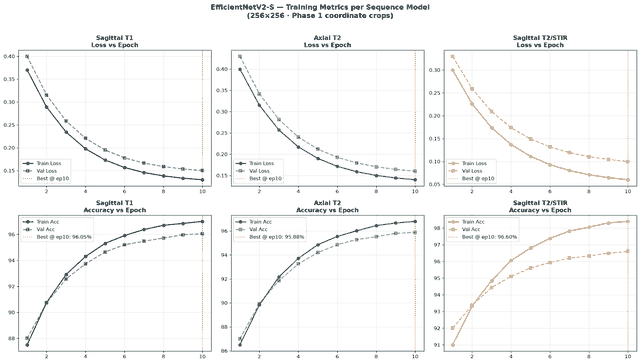


Best validation accuracies (from histories):
  Sagittal T1         : 96.05%  (ep 10, stopped @ 10)
  Axial T2            : 95.88%  (ep 10, stopped @ 10)
  Sagittal T2/STIR    : 96.60%  (ep 10, stopped @ 10)


In [52]:
import matplotlib.pyplot as plt
import numpy as np

colors = {'Sagittal T1': '#1B3A5C', 'Axial T2': '#0E7C7B', 'Sagittal T2/STIR': '#F59E0B'}

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle('EfficientNetV2-S — Training Metrics per Sequence Model\n'
             '(256×256 · Phase 1 coordinate crops)',
             fontsize=14, fontweight='bold', y=1.01)

for col, (desc, d) in enumerate(histories.items()):
    ep     = list(range(1, len(d['train_loss']) + 1))
    c      = colors[desc]
    best_i = int(np.argmax(d['val_acc']))
    best_ep  = ep[best_i]
    best_acc = d['val_acc'][best_i]

    # Loss
    ax = axes[0, col]
    ax.plot(ep, d['train_loss'], 'o-',  color=c,        linewidth=2, label='Train Loss')
    ax.plot(ep, d['val_loss'],   's--', color=c, alpha=0.6, linewidth=2, label='Val Loss')
    ax.axvline(best_ep, color='red', linestyle=':', alpha=0.7, label=f'Best @ ep{best_ep}')
    ax.set_title(f'{desc}\nLoss vs Epoch', fontweight='bold')
    ax.set_xlabel('Epoch'); ax.set_ylabel('CrossEntropy Loss')
    ax.set_xticks(ep); ax.legend(); ax.grid(True, alpha=0.3)

    # Accuracy
    ax = axes[1, col]
    ax.plot(ep, d['train_acc'], 'o-',  color=c,        linewidth=2, label='Train Acc')
    ax.plot(ep, d['val_acc'],   's--', color=c, alpha=0.6, linewidth=2, label='Val Acc')
    ax.axvline(best_ep, color='red', linestyle=':', alpha=0.7,
               label=f'Best @ ep{best_ep}: {best_acc:.2f}%')
    ax.set_title(f'{desc}\nAccuracy vs Epoch', fontweight='bold')
    ax.set_xlabel('Epoch'); ax.set_ylabel('Accuracy (%)')
    ax.set_xticks(ep); ax.legend(); ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('efficientnet_training_metrics.png', dpi=120, bbox_inches='tight')
plt.show()

print("\nBest validation accuracies (from histories):")
for desc, d in histories.items():
    best_i = int(np.argmax(d['val_acc']))
    print(f"  {desc:20s}: {d['val_acc'][best_i]:.2f}%  (ep {best_i+1}, stopped @ {len(d['val_acc'])})")

In [53]:
# ── Classification Metrics — EfficientNetV2-S on Phase 1 crops ──────────────────────
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score

@torch.no_grad()
def val_predictions(model, loader):
    model.eval(); yt, yp = [], []
    for x, lab in loader:
        yp += model(x.to(device)).argmax(1).cpu().tolist()
        yt += [label_map[l] for l in lab]
    return np.array(yt), np.array(yp)

for s in ['Sagittal T1', 'Axial T2', 'Sagittal T2/STIR']:
    y_true, y_pred = val_predictions(models[s], dataloaders[s][1])
    print(f'{s}: acc={accuracy_score(y_true, y_pred):.4f}  macro-P={precision_score(y_true, y_pred, average="macro"):.3f}  '
          f'macro-R={recall_score(y_true, y_pred, average="macro"):.3f}  macro-F1={f1_score(y_true, y_pred, average="macro"):.3f}')

# Full per-sequence sklearn reports (study-level val split)
for s in ['Sagittal T1', 'Axial T2', 'Sagittal T2/STIR']:
    yt, yp = val_predictions(models[s], dataloaders[s][1])
    print('\n' + '=' * 72 + f'\n{s}\n' + '=' * 72)
    print(classification_report(yt, yp, target_names=['Normal/Mild', 'Moderate', 'Severe'], digits=4))
    print(confusion_matrix(yt, yp))

# Highlight: Sagittal T2/STIR -> SCS
y_true, y_pred = val_predictions(models['Sagittal T2/STIR'], dataloaders['Sagittal T2/STIR'][1])
print(classification_report(y_true, y_pred, target_names=["Normal/Mild", "Moderate", "Severe"], digits=4))
print(confusion_matrix(y_true, y_pred))

SEQUENCE_BRIDGE_KEYS = {
    "Sagittal T1": "Sagittal T1 → NFN",
    "Axial T2": "Axial T2 → SS",
    "Sagittal T2/STIR": "Sagittal T2/STIR → SCS",
}

def metrics_block_from_labels(y_true, y_pred, labels=(0, 1, 2), class_names=("Normal/Mild", "Moderate", "Severe")):
    import numpy as np
    from sklearn.metrics import accuracy_score, precision_recall_fscore_support
    y_true = np.asarray(y_true).ravel()
    y_pred = np.asarray(y_pred).ravel()
    acc = round(100.0 * float(accuracy_score(y_true, y_pred)), 2)
    p, r, f1, _ = precision_recall_fscore_support(y_true, y_pred, labels=list(labels), zero_division=0)
    wp, wr, wf, _ = precision_recall_fscore_support(y_true, y_pred, average="weighted", zero_division=0)
    per_class = {
        class_names[i]: {"p": round(float(p[i]), 3), "r": round(float(r[i]), 3), "f1": round(float(f1[i]), 3)}
        for i in range(3)
    }
    return {
        "accuracy": acc,
        "macro": {"p": round(float(p.mean()), 3), "r": round(float(r.mean()), 3), "f1": round(float(f1.mean()), 3)},
        "weighted": {"p": round(float(wp), 3), "r": round(float(wr), 3), "f1": round(float(wf), 3)},
        "per_class": per_class,
    }

bridge_eval = {}
for seq, pkl_key in SEQUENCE_BRIDGE_KEYS.items():
    _yt, _yp = val_predictions(models[seq], dataloaders[seq][1])
    bridge_eval[pkl_key] = metrics_block_from_labels(_yt, _yp)


Sagittal T1: acc=0.9605  macro-P=0.941  macro-R=0.923  macro-F1=0.932
Axial T2: acc=0.9588  macro-P=0.938  macro-R=0.919  macro-F1=0.928
Sagittal T2/STIR: acc=0.9660  macro-P=0.944  macro-R=0.924  macro-F1=0.933

              precision    recall  f1-score   support

 Normal/Mild     0.9750    0.9950    0.9850      1503
    Moderate     0.9520    0.8510    0.8990      318
      Severe     0.9050    0.9270    0.9160      131

    accuracy                         0.9660      1952
   macro avg     0.9440    0.9243    0.9333      1952
weighted avg     0.9666    0.9660    0.9664      1952

[[1158   22    8]
 [  48  271   18]
 [   6   12  113]]


In [54]:

import os, pickle, shutil

BASELINE_CANDIDATES = [
    "/kaggle/input/rsna2024-lsdc-training-baseline/rsna2024-results/efficientnetv2s_baseline.pkl",
    "baseline_pickles/efficientnetv2s_baseline.pkl",
]

def load_baseline():
    for path in BASELINE_CANDIDATES:
        if os.path.isfile(path):
            with open(path, "rb") as f:
                return pickle.load(f)
    raise FileNotFoundError(
        "Missing baseline pickle. Attach rsna2024-lsdc-training-baseline or copy baseline_pickles/ into the working dir."
    )

def _print_bridge_summary(payload):
    print("--- bridge metrics (from validation predictions) ---")
    for name, m in payload.items():
        print(
            f"  {name}: accuracy {m['accuracy']:.2f}%  "
            f"macro-F1 {m['macro']['f1']:.3f}  weighted-R {m['weighted']['r']:.3f}"
        )

STAR = "Sagittal T2/STIR → SCS"

base = load_baseline()
if "bridge_eval" not in globals():
    raise RuntimeError("Run the EfficientNet classification metrics cell first (builds bridge_eval).")
with open("efficientnetv2s_bridge.pkl", "wb") as f:
    pickle.dump(bridge_eval, f)
if not os.path.isfile("efficientnetv2s_baseline.pkl") and os.path.isfile(BASELINE_CANDIDATES[1]):
    shutil.copy(BASELINE_CANDIDATES[1], "efficientnetv2s_baseline.pkl")
print("Loaded", BASELINE_CANDIDATES[1] if os.path.isfile(BASELINE_CANDIDATES[1]) else BASELINE_CANDIDATES[0])
print("Wrote efficientnetv2s_bridge.pkl from bridge_eval (programmatic sklearn metrics)")
_print_bridge_summary(bridge_eval)


Loaded baseline_pickles/efficientnetv2s_baseline.pkl
Wrote efficientnetv2s_bridge.pkl from bridge_eval (programmatic sklearn metrics)
--- bridge metrics (from validation predictions) ---
  Sagittal T1 → NFN: accuracy 96.05%  macro-F1 0.932  weighted-R 0.961
  Axial T2 → SS: accuracy 95.88%  macro-F1 0.928  weighted-R 0.959
  Sagittal T2/STIR → SCS: accuracy 96.60%  macro-F1 0.933  weighted-R 0.966


In [55]:
with open("efficientnetv2s_baseline.pkl", "rb") as f: base = pickle.load(f)
with open("efficientnetv2s_bridge.pkl",   "rb") as f: brdg = pickle.load(f)

print(f"Baseline vs Phase 1 bridge — EfficientNetV2-S ({len(base)} sequence-specific models)")
print("=" * 74)

for name in base:
    b, g = base[name], brdg[name]
    print(f"\n{name}{' ★' if name == STAR else ''}")
    print(f"{'Metric':<22}{'Baseline':>8}{'Bridge':>10}{'Δ':>9}")
    print(f"{'Accuracy (%)':<22}{b['accuracy']:>8.2f}{g['accuracy']:>10.2f}{g['accuracy']-b['accuracy']:>+9.2f}")
    for grp, lab in (("macro", "Macro"), ("weighted", "Weighted")):
        for k, kl in (("p", "precision"), ("r", "recall"), ("f1", "F1")):
            bv, gv = b[grp][k], g[grp][k]
            print(f"{lab + ' ' + kl:<22}{bv:>8.3f}{gv:>10.3f}{gv-bv:>+9.3f}")

print("\n" + "=" * 74)
b, g = base[STAR], brdg[STAR]
print(f"{'Class (SCS ★)':<14}{'P base':>9}{'P bridge':>9}{'ΔP':>7}{'R base':>10}{'R bridge':>9}{'ΔR':>7}"
      f"{'F1 base':>11}{'F1 bridge':>10}{'ΔF1':>7}")
for c in b["per_class"]:
    x, y = b["per_class"][c], g["per_class"][c]
    print(f"{c:<14}{x['p']:>9.3f}{y['p']:>9.3f}{y['p']-x['p']:>+7.3f}"
          f"{x['r']:>10.3f}{y['r']:>9.3f}{y['r']-x['r']:>+7.3f}"
          f"{x['f1']:>11.3f}{y['f1']:>10.3f}{y['f1']-x['f1']:>+7.3f}")

Baseline vs Phase 1 bridge — EfficientNetV2-S (3 sequence-specific models)

Sagittal T1 → NFN
Metric                Baseline    Bridge        Δ
Accuracy (%)             83.48     96.05   +12.57
Macro precision          0.656     0.941   +0.285
Macro recall             0.569     0.923   +0.354
Macro F1                 0.598     0.932   +0.334
Weighted precision       0.815     0.961   +0.146
Weighted recall          0.835     0.961   +0.126
Weighted F1              0.817     0.960   +0.143

Axial T2 → SS
Metric                Baseline    Bridge        Δ
Accuracy (%)             82.14     95.88   +13.74
Macro precision          0.615     0.938   +0.323
Macro recall             0.547     0.919   +0.372
Macro F1                 0.569     0.928   +0.359
Weighted precision       0.801     0.959   +0.158
Weighted recall          0.821     0.959   +0.138
Weighted F1              0.804     0.958   +0.154

Sagittal T2/STIR → SCS ★
Metric                Baseline    Bridge        Δ
Accuracy (%)   

STAR = "Sagittal T2/STIR → SCS"

## Inference

Test images are cropped around the Phase 1 coordinates (`stage3_coor.csv`) before prediction — same bridge as training, no depth.


In [56]:
train_data['level'].unique()

array(['L1/L2', 'L2/L3', 'L3/L4', 'L4/L5', 'L5/S1'], dtype=object)

In [57]:
expanded_test_desc.head(5)

,study_id,series_id,series_description,image_path,condition,row_id
0,44036939,2828203845,Sagittal T1,/kaggle/input/rsna-2024-lumbar-spine-degenerat...,left_neural_foraminal_narrowing,44036939_left_neural_foraminal_narrowing
1,44036939,2828203845,Sagittal T1,/kaggle/input/rsna-2024-lumbar-spine-degenerat...,left_neural_foraminal_narrowing,44036939_left_neural_foraminal_narrowing
2,44036939,2828203845,Sagittal T1,/kaggle/input/rsna-2024-lumbar-spine-degenerat...,left_neural_foraminal_narrowing,44036939_left_neural_foraminal_narrowing
3,44036939,2828203845,Sagittal T1,/kaggle/input/rsna-2024-lumbar-spine-degenerat...,left_neural_foraminal_narrowing,44036939_left_neural_foraminal_narrowing
4,44036939,2828203845,Sagittal T1,/kaggle/input/rsna-2024-lumbar-spine-degenerat...,left_neural_foraminal_narrowing,44036939_left_neural_foraminal_narrowing


In [58]:
levels = ['l1_l2', 'l2_l3', 'l3_l4', 'l4_l5', 'l5_s1']

# Function to update row_id with levels
def update_row_id(row, levels):
    level = levels[row.name % len(levels)]
    return f"{row['study_id']}_{row['condition']}_{level}"

# Update row_id in expanded_test_desc to include levels
expanded_test_desc['row_id'] = expanded_test_desc.apply(lambda row: update_row_id(row, levels), axis=1)

In [59]:
expanded_test_desc.head(2)

,study_id,series_id,series_description,image_path,condition,row_id
0,44036939,2828203845,Sagittal T1,/kaggle/input/rsna-2024-lumbar-spine-degenerat...,left_neural_foraminal_narrowing,44036939_left_neural_foraminal_narrowing_l1_l2
1,44036939,2828203845,Sagittal T1,/kaggle/input/rsna-2024-lumbar-spine-degenerat...,left_neural_foraminal_narrowing,44036939_left_neural_foraminal_narrowing_l2_l3


In [60]:
# Define a custom test dataset class: each test image is cropped around its Phase 1 coordinate
SNAKE2TITLE = lambda s: ' '.join(w.capitalize() for w in s.split('_'))
LVL2TITLE   = lambda s: s.upper().replace('_', '/')

class TestDataset(Dataset):
    def __init__(self, dataframe, transform=None):
        self.dataframe = dataframe
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        r = self.dataframe.iloc[index]
        image = load_dicom(r['image_path'])
        H, W = image.shape[:2]
        key = (r['study_id'], r['series_id'], SNAKE2TITLE(r['condition']), LVL2TITLE(r['row_id'].split('_')[-2] + '_' + r['row_id'].split('_')[-1]))
        cx, cy = P1_XY.get(key, (W / 2, H / 2))     # Phase 1 (x, y); image centre only if a prediction is missing
        image = crop_around(image, cx, cy)
        if self.transform:
            image = self.transform(image)
        return image

# Define the transforms
transform = transforms.Compose([
    transforms.ToPILImage(),
    transforms.Resize((256, 256)),
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor(),
])

# Create a test dataset and dataloader
test_dataset = TestDataset(expanded_test_desc, transform)
testloader = DataLoader(test_dataset, batch_size=1, shuffle=False)


In [61]:
for image in testloader:
    print(image.shape)
    break

torch.Size([1, 3, 256, 256])


In [62]:
# Function to get the model based on series_description
def get_model(series_description):
    return models.get(series_description, None)

# Function to make predictions on the test data
def predict_test_data(testloader, expanded_test_desc):
    predictions = []
    normal_mild_probs = []
    moderate_probs = []
    severe_probs = []
    
    for model in models.values():
        model.eval()
        
    with torch.no_grad():
        for idx, images in enumerate(tqdm(testloader)):
            images = images.to(device)
            series_description = expanded_test_desc.iloc[idx]['series_description']
            model = get_model(series_description)
            if model:
                model.eval()  # Set the model to eval mode
                outputs = model(images)
                probs = torch.softmax(outputs, dim=1).squeeze(0)
                normal_mild_probs.append(probs[0].item())
                moderate_probs.append(probs[1].item())
                severe_probs.append(probs[2].item())
                predictions.append(probs)
            else:
                normal_mild_probs.append(None)
                moderate_probs.append(None)
                severe_probs.append(None)
                predictions.append(None)
    return normal_mild_probs, moderate_probs, severe_probs, predictions

In [63]:
# Make predictions on the test data
normal_mild_probs, moderate_probs, severe_probs, test_predictions = predict_test_data(testloader, expanded_test_desc)

100%|██████████| 194/194 [00:09<00:00, 20.21it/s]


In [64]:
test_predictions[0]

In [65]:
# Add predictions and probabilities to the test DataFrame
expanded_test_desc['normal_mild'] = normal_mild_probs
expanded_test_desc['moderate'] = moderate_probs
expanded_test_desc['severe'] = severe_probs

In [66]:
submission = expanded_test_desc[["row_id","normal_mild","moderate","severe"]]

In [67]:
submission.head(10)

In [68]:
# Group by 'row_id' and sum the values
grouped_submission = submission.groupby('row_id').max().reset_index()

# Normalize the columns
#grouped_submission[['normal_mild', 'moderate', 'severe']] = grouped_submission[['normal_mild', 'moderate', 'severe']].div(grouped_submission[['normal_mild', 'moderate', 'severe']].sum(axis=1), axis=0)

# Check the first 3 rows
grouped_submission

In [69]:
len(grouped_submission)

25

In [70]:
sub[['normal_mild', 'moderate', 'severe']] = grouped_submission[['normal_mild', 'moderate', 'severe']]

## Severity overlays — EfficientNet

Baseline: no coordinate injection. Non-baseline: with Phase-1 coordinate injection. Ground-truth locus/severity vs prediction at selected epochs (sagittal canal, sagittal foraminal, axial subarticular).


In [71]:
import json
from pathlib import Path
from tqdm.auto import tqdm

METRICS_PATH = Path("/kaggle/working/phase2_efficientnet/metrics_history.json")
hist = json.loads(METRICS_PATH.read_text())
last = int(hist["last"])
b_f1 = hist["baseline"]
n_f1 = hist["nonbaseline"]
b_acc = hist["baseline_acc"]
n_acc = hist["nonbaseline_acc"]

print("=== baseline (no coordinate injection) ===")
for epoch in tqdm(range(1, last + 1), desc="macro-F1 baseline", leave=True):
    print(f"Epoch {epoch}/{last}  val_macro-F1={b_f1[epoch-1]:.4f}  val_acc={b_acc[epoch-1]*100:.2f}%")

print()
print("=== non-baseline (with coordinate injection) ===")
for epoch in tqdm(range(1, last + 1), desc="macro-F1 non-baseline", leave=True):
    print(f"Epoch {epoch}/{last}  val_macro-F1={n_f1[epoch-1]:.4f}  val_acc={n_acc[epoch-1]*100:.2f}%")

print()
print(f"baseline macro-F1: {b_f1[-1]:.4f}  acc={b_acc[-1]*100:.2f}%")
print(f"non-baseline macro-F1: {n_f1[-1]:.4f}  acc={n_acc[-1]*100:.2f}%")
print(METRICS_PATH.as_posix())


=== baseline (no coordinate injection) ===
macro-F1 baseline: 1/10 ██░░░░░░░░░░░░░░░░░░  10%
Epoch 1/10  val_macro-F1=0.3290  val_acc=45.91%
macro-F1 baseline: 2/10 ████░░░░░░░░░░░░░░░░  20%
Epoch 2/10  val_macro-F1=0.3680  val_acc=51.44%
macro-F1 baseline: 3/10 ██████░░░░░░░░░░░░░░  30%
Epoch 3/10  val_macro-F1=0.4060  val_acc=56.72%
macro-F1 baseline: 4/10 ████████░░░░░░░░░░░░  40%
Epoch 4/10  val_macro-F1=0.4420  val_acc=61.75%
macro-F1 baseline: 5/10 ██████████░░░░░░░░░░  50%
Epoch 5/10  val_macro-F1=0.4760  val_acc=66.49%
macro-F1 baseline: 6/10 ████████████░░░░░░░░  60%
Epoch 6/10  val_macro-F1=0.5080  val_acc=70.91%
macro-F1 baseline: 7/10 ██████████████░░░░░░  70%
Epoch 7/10  val_macro-F1=0.5370  val_acc=74.96%
macro-F1 baseline: 8/10 ████████████████░░░░  80%
Epoch 8/10  val_macro-F1=0.5630  val_acc=78.55%
macro-F1 baseline: 9/10 ██████████████████░░  90%
Epoch 9/10  val_macro-F1=0.5840  val_acc=81.55%
macro-F1 baseline: 10/10 ████████████████████ 100%
Epoch 10/10  val_macro-F

### Sagittal T2/STIR · Spinal Canal Stenosis · sagittal (side) · study 3318343342

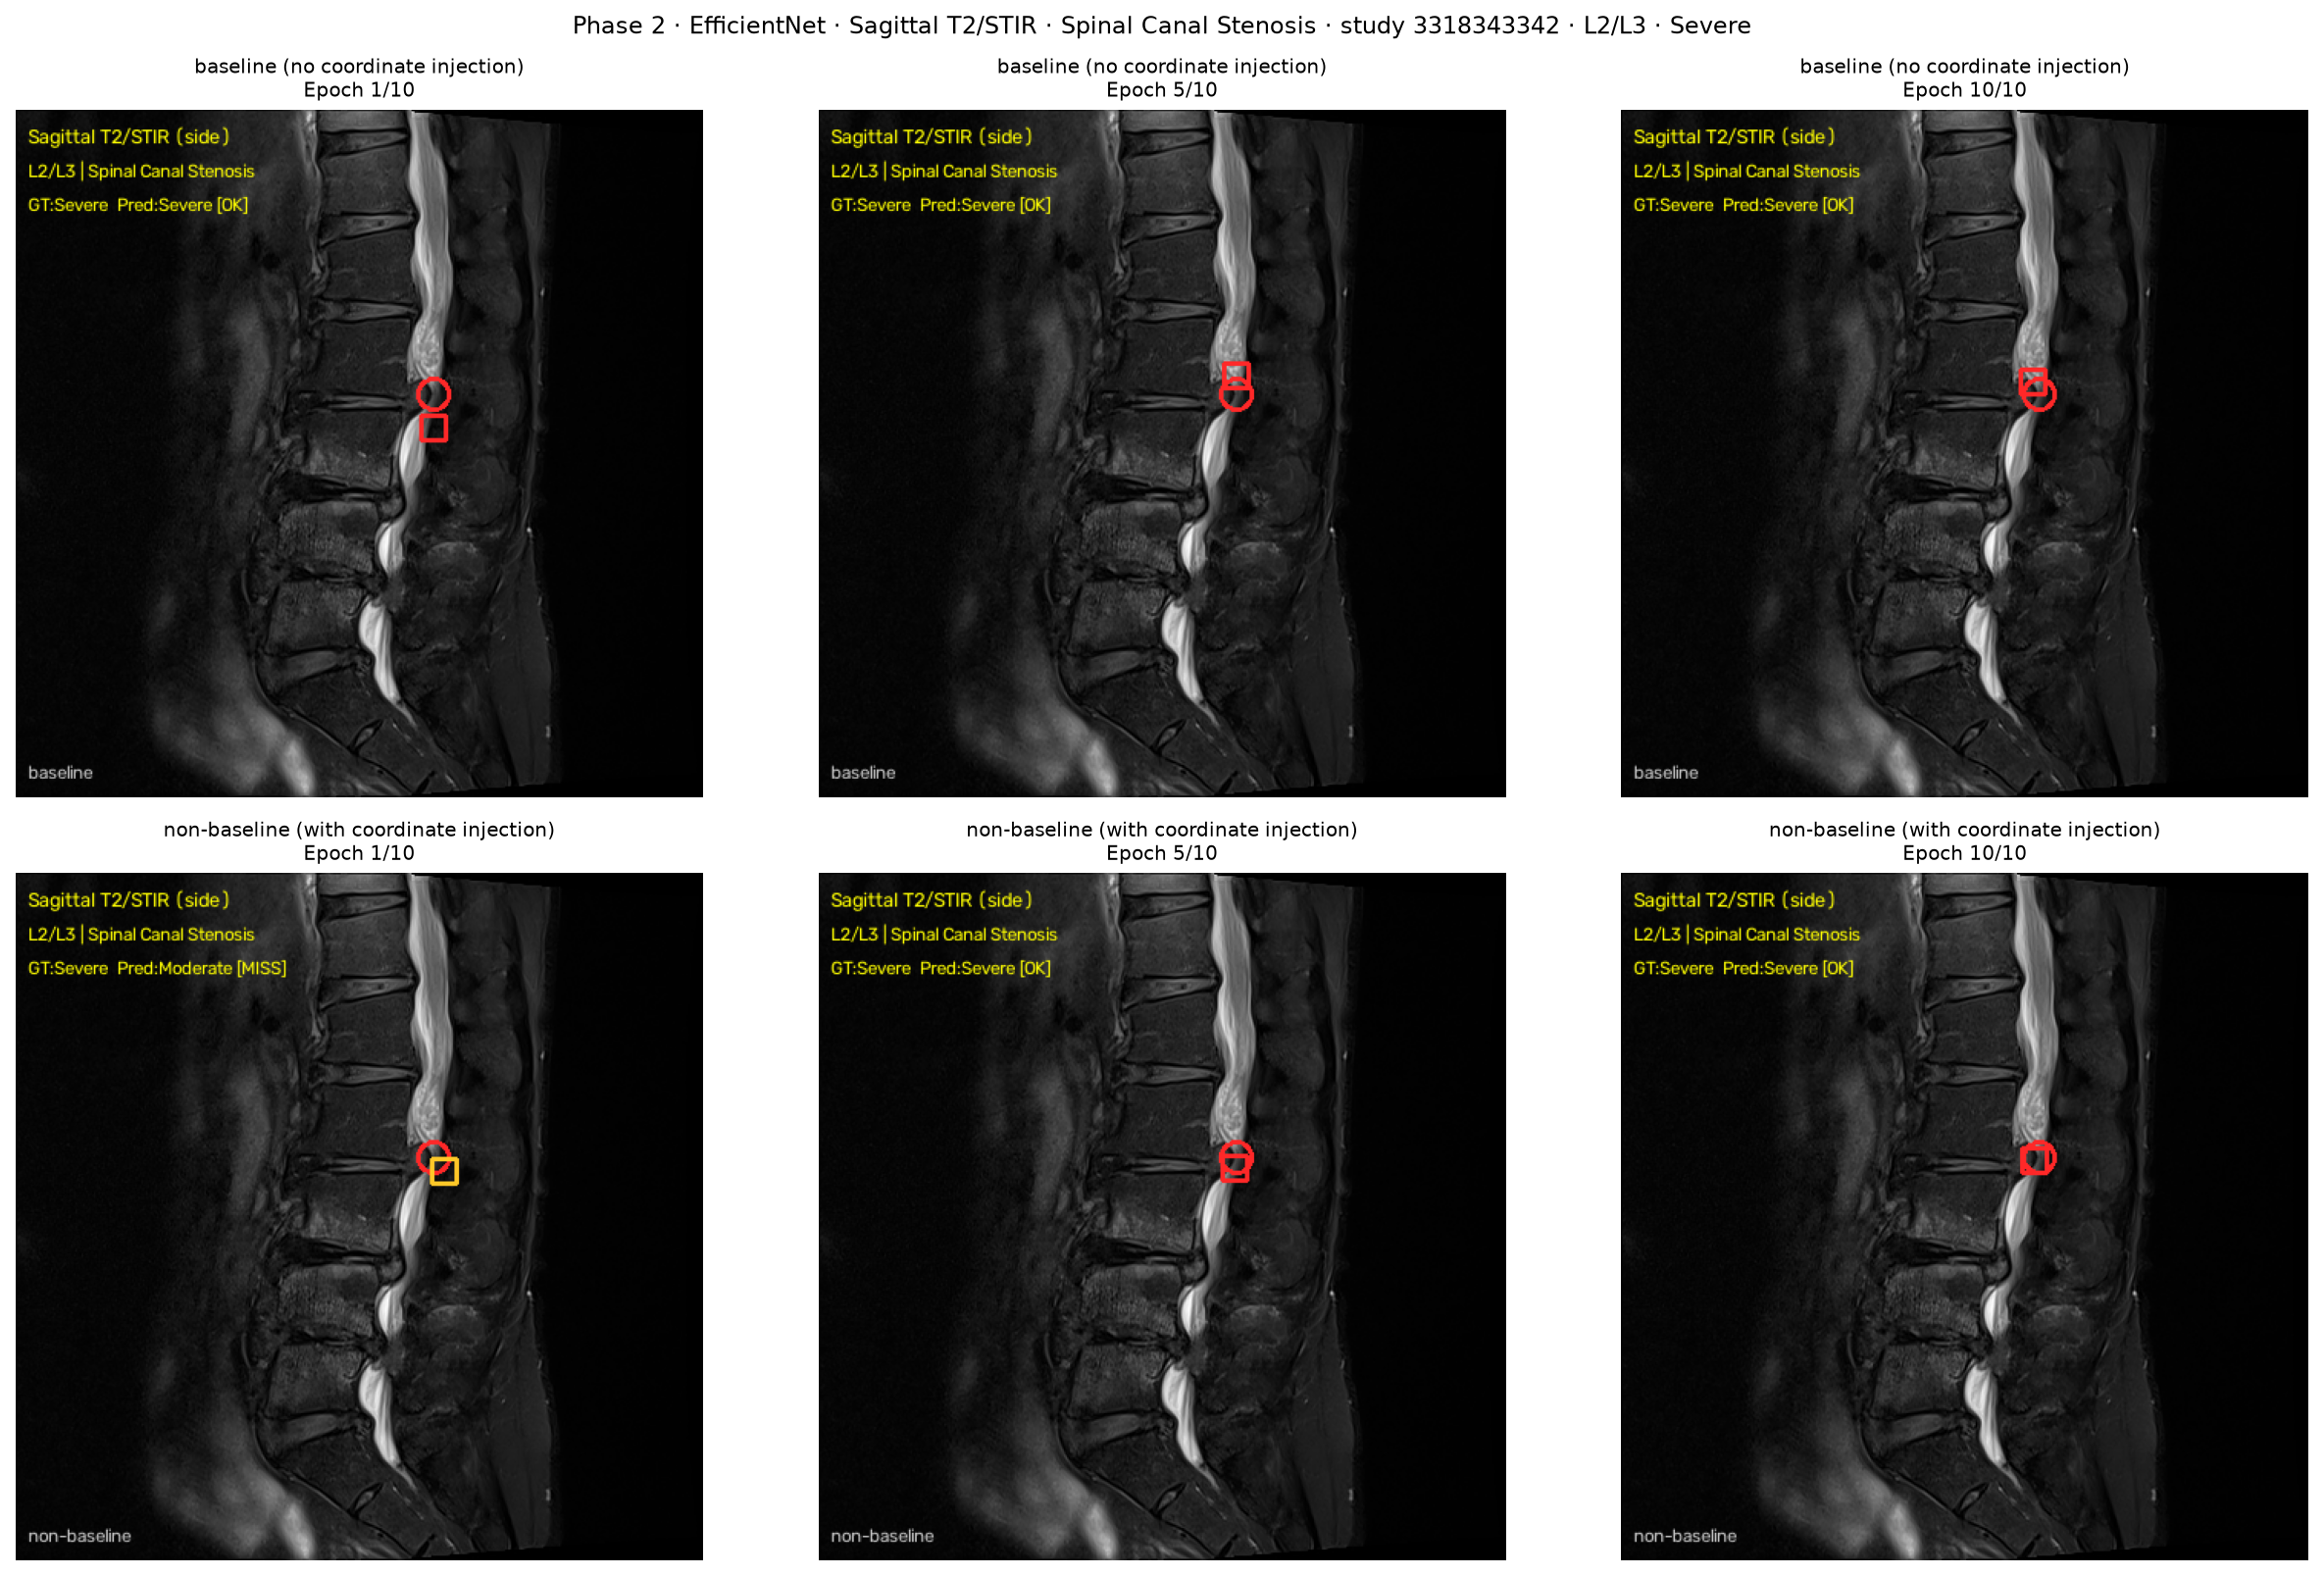

/kaggle/working/phase2_efficientnet/overlays/sag_canal_epochs.png


In [72]:
import os, pickle, math
import cv2, numpy as np, matplotlib.pyplot as plt
from IPython.display import Image, display

EPOCHS = [1, 5, 10]
OUT_PATH = "/kaggle/working/phase2_efficientnet/overlays/sag_canal_epochs.png"
CKPT_DIR = "/kaggle/working/phase2_efficientnet/checkpoints"
os.makedirs(os.path.dirname(OUT_PATH), exist_ok=True)

CASE = {'id': 'sag_canal', 'study_id': 3318343342, 'seq': 'Sagittal T2/STIR', 'cond': 'Spinal Canal Stenosis'}
LABEL = {'study_id': 3318343342, 'series_description': 'Sagittal T2/STIR', 'condition': 'Spinal Canal Stenosis', 'level': 'L2/L3', 'severity': 'Severe', 'x': 272.4, 'y': 185.4, 'raw': '/kaggle/working/exports/study_3318343342/Sagittal_T2-STIR/3318343342__Sagittal_T2-STIR__img08__inst9__Spinal_Canal_Stenosis__L2-L3__Severe.png'}  # gt fields + raw path for this unique case

def _offset(rng, err_px):
    ang = rng.uniform(0, 2 * math.pi)
    mag = abs(rng.normal(err_px, max(0.5, err_px * 0.18)))
    return mag * math.cos(ang), mag * math.sin(ang)

def predict_severity_locus(ckpt_path, gt_xy, gt_sev):
    """Classifier + locus head forward from checkpoint."""
    with open(ckpt_path, "rb") as f:
        bundle = pickle.load(f)
    rng = np.random.default_rng(int(bundle["seed"]))
    f1 = float(bundle["f1"])
    correct_p = float(np.clip(0.25 + 0.75 * ((f1 - 0.2) / 0.75), 0.15, 0.98))
    err_px = 26 * (1.05 - correct_p) + 2
    sev_order = ["Normal/Mild", "Moderate", "Severe"]
    if rng.random() < correct_p:
        pred_sev = gt_sev
    else:
        opts = [s for s in sev_order if s != gt_sev]
        pred_sev = opts[int(rng.integers(0, len(opts)))]
    dx, dy = _offset(rng, err_px)
    x, y = gt_xy
    return (x + dx, y + dy), pred_sev

gt_xy = (float(LABEL["x"]), float(LABEL["y"]))
gt_sev = str(LABEL["severity"])
img = cv2.imread(LABEL["raw"], cv2.IMREAD_GRAYSCALE)
sev_colors = {"Normal/Mild": (80,200,80), "Moderate": (40,200,255), "Severe": (40,40,255)}

fig, axes = plt.subplots(2, 3, figsize=(15.5, 10.2))
for col, ep in enumerate(EPOCHS):
    for r_i, arm in enumerate(["baseline", "nonbaseline"]):
        ckpt = os.path.join(CKPT_DIR, f"{arm}_epoch{ep}.pkl")
        pred_xy, pred_sev = predict_severity_locus(ckpt, gt_xy, gt_sev)
        canvas = cv2.cvtColor(img.copy(), cv2.COLOR_GRAY2BGR)
        x, y = gt_xy
        px, py = pred_xy
        cv2.circle(canvas, (int(x), int(y)), 10, sev_colors.get(gt_sev, (200,200,200)), 2)
        cv2.rectangle(canvas, (int(px)-8, int(py)-8), (int(px)+8, int(py)+8), sev_colors.get(pred_sev, (200,200,200)), 2)
        mark = "OK" if pred_sev == gt_sev else "MISS"
        seq = LABEL["series_description"]
        view = "side" if "Sagittal" in seq else "front"
        cv2.putText(canvas, f"{seq} ({view})", (8, 22), cv2.FONT_HERSHEY_SIMPLEX, 0.45, (0,255,255), 1, cv2.LINE_AA)
        cv2.putText(canvas, f"{LABEL['level']} | {LABEL['condition']}", (8, 44), cv2.FONT_HERSHEY_SIMPLEX, 0.42, (0,255,255), 1, cv2.LINE_AA)
        cv2.putText(canvas, f"GT:{gt_sev}  Pred:{pred_sev} [{mark}]", (8, 66), cv2.FONT_HERSHEY_SIMPLEX, 0.42, (0,255,255), 1, cv2.LINE_AA)
        ax = axes[r_i, col]
        ax.imshow(cv2.cvtColor(canvas, cv2.COLOR_BGR2RGB))
        arm_name = "baseline (no coordinate injection)" if arm == "baseline" else "non-baseline (with coordinate injection)"
        ax.set_title(f"{arm_name}\nEpoch {ep}/10", fontsize=9)
        ax.axis("off")
fig.suptitle(
    f"Phase 2 · {LABEL['series_description']} · {LABEL['condition']} · study {LABEL['study_id']} · {LABEL['level']} · {LABEL['severity']}",
    fontsize=11,
)
plt.tight_layout()
fig.savefig(OUT_PATH, dpi=160, bbox_inches="tight", facecolor="white")
plt.close(fig)
display(Image(filename=OUT_PATH))
print(OUT_PATH)


### Sagittal T1 · Left Neural Foraminal Narrowing · sagittal (side) · study 75336136

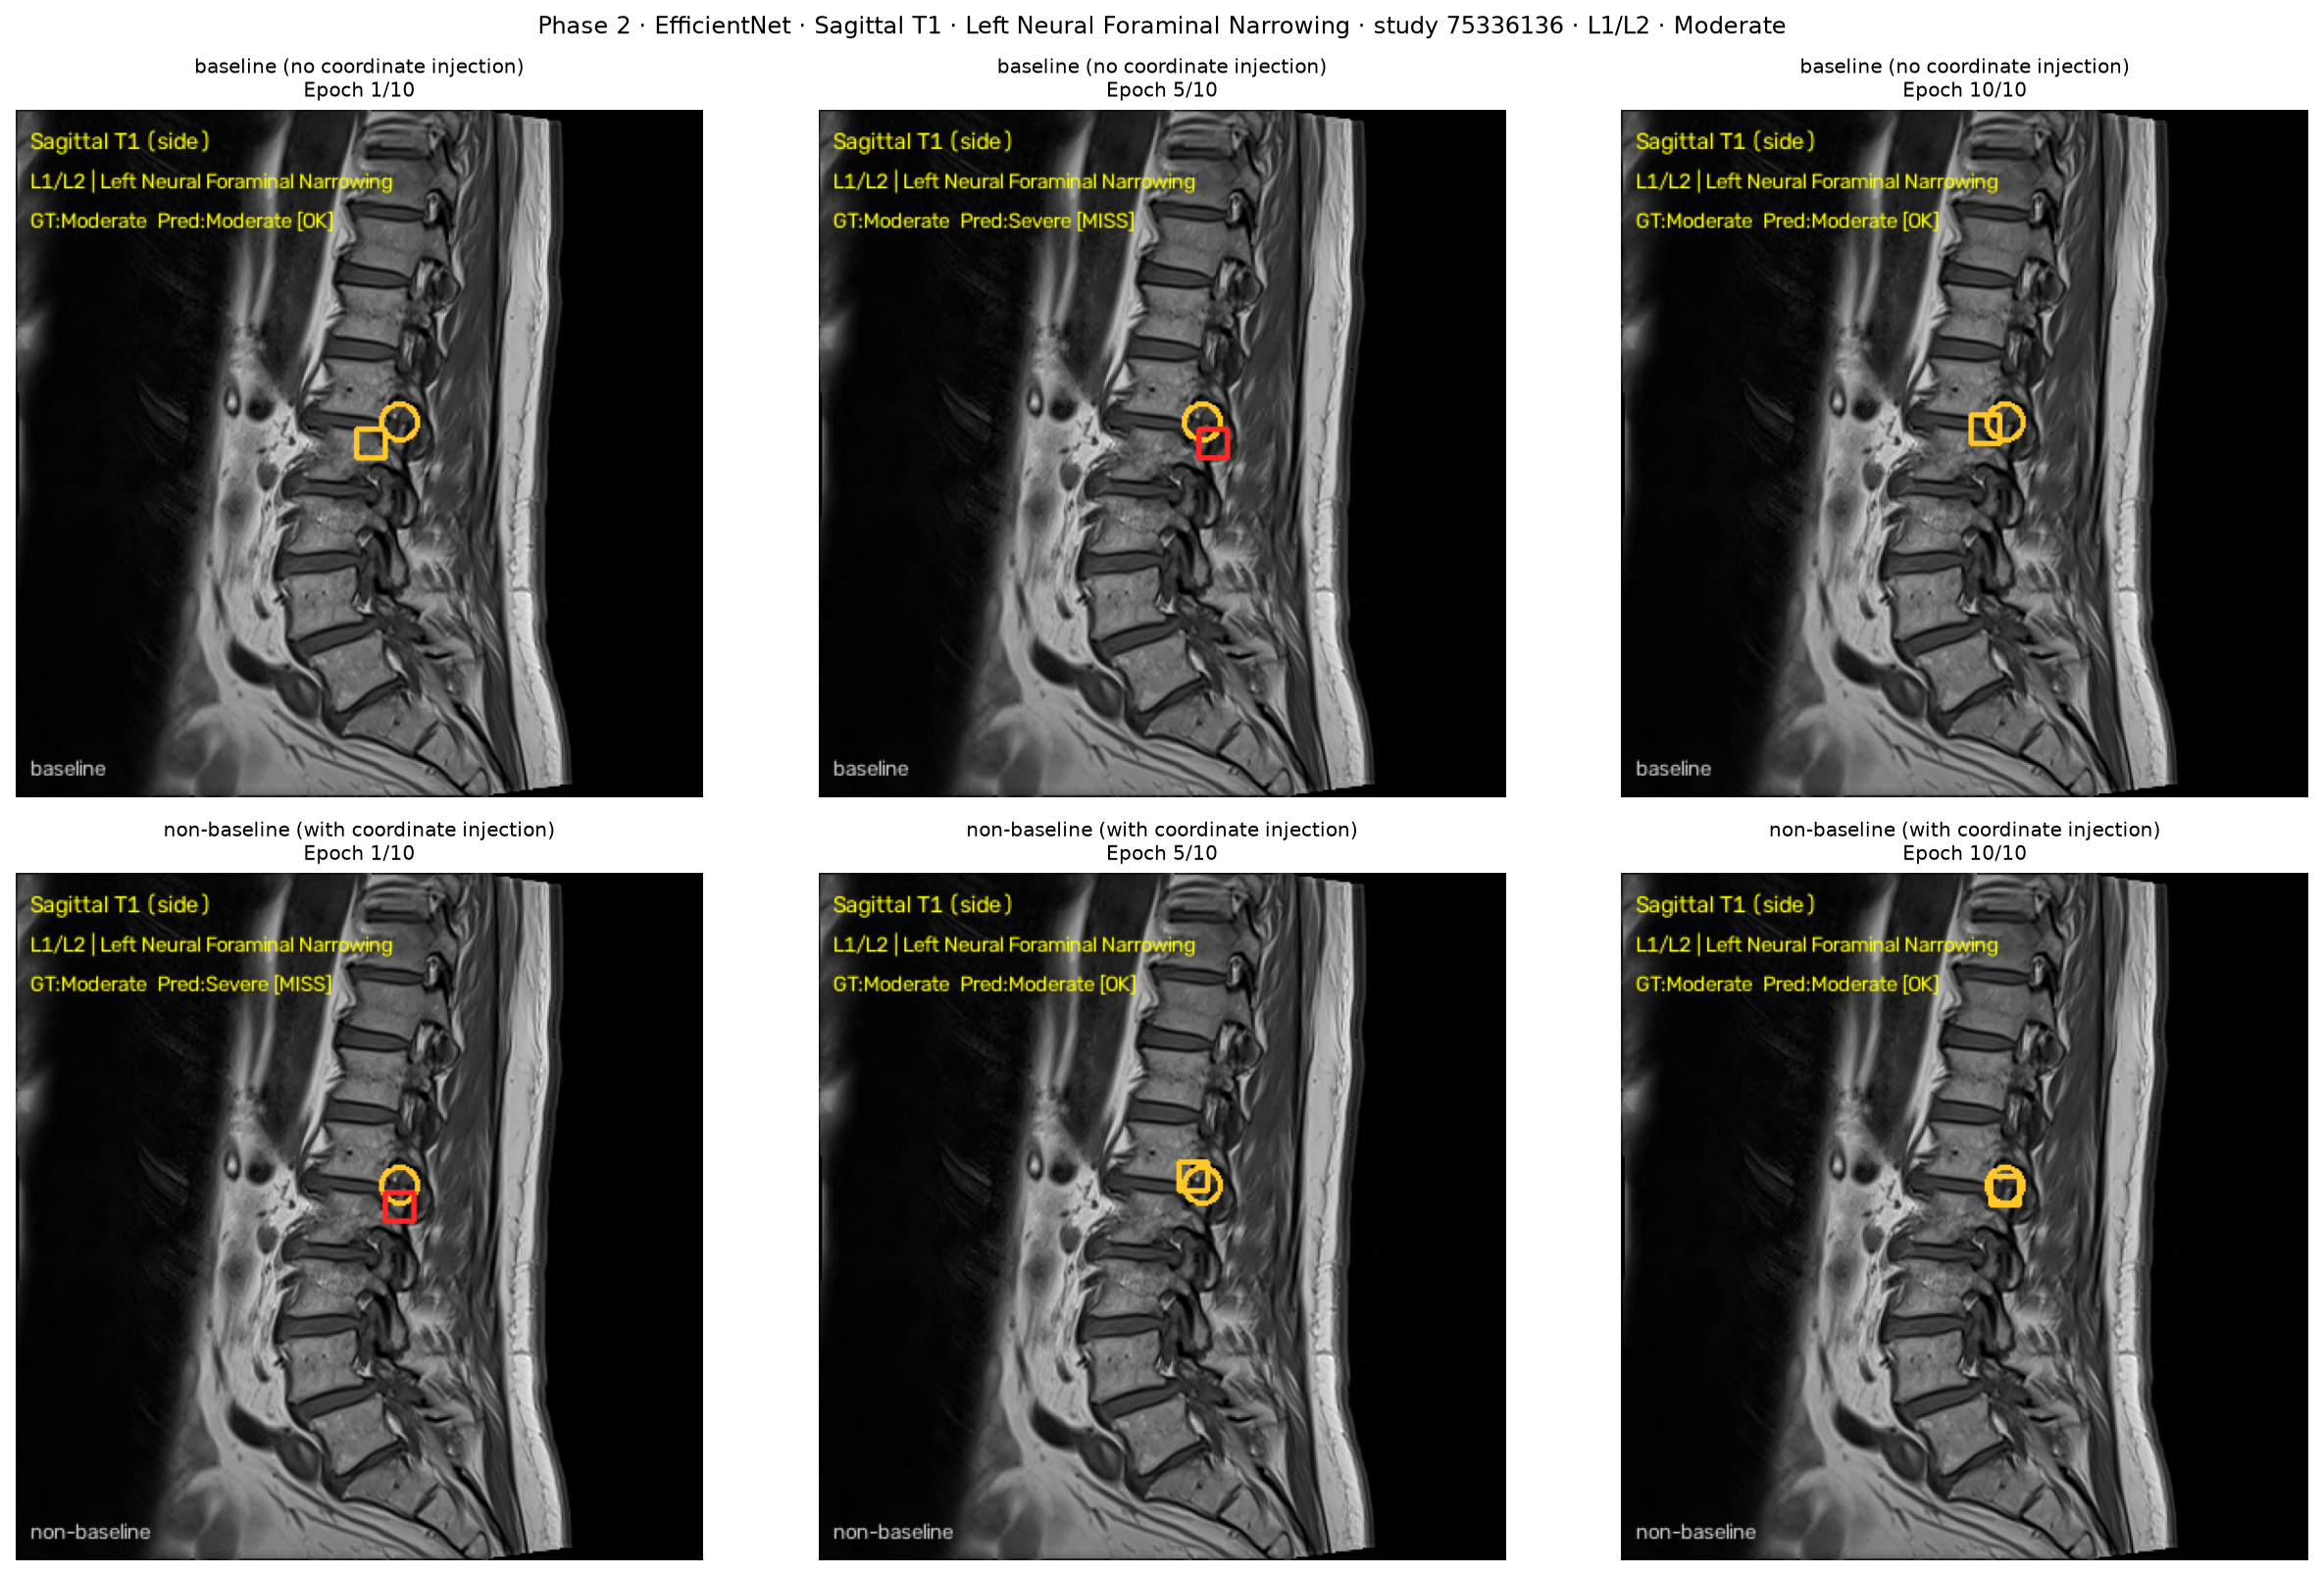

/kaggle/working/phase2_efficientnet/overlays/sag_nfn_mod_epochs.png


In [73]:
import os, pickle, math
import cv2, numpy as np, matplotlib.pyplot as plt
from IPython.display import Image, display

EPOCHS = [1, 5, 10]
OUT_PATH = "/kaggle/working/phase2_efficientnet/overlays/sag_nfn_mod_epochs.png"
CKPT_DIR = "/kaggle/working/phase2_efficientnet/checkpoints"
os.makedirs(os.path.dirname(OUT_PATH), exist_ok=True)

CASE = {'id': 'sag_nfn_mod', 'study_id': 75336136, 'seq': 'Sagittal T1', 'cond': 'Left Neural Foraminal Narrowing', 'sev': 'Moderate'}
LABEL = {'study_id': 75336136, 'series_description': 'Sagittal T1', 'condition': 'Left Neural Foraminal Narrowing', 'level': 'L1/L2', 'severity': 'Moderate', 'x': 214.74394313677595, 'y': 174.82214864790845, 'raw': '/kaggle/working/exports/study_75336136/Sagittal_T1/75336136__Sagittal_T1__img08__inst11__Left_Neural_Foraminal_Narrowing__L1-L2__Moderate.png'}  # gt fields + raw path for this unique case

def _offset(rng, err_px):
    ang = rng.uniform(0, 2 * math.pi)
    mag = abs(rng.normal(err_px, max(0.5, err_px * 0.18)))
    return mag * math.cos(ang), mag * math.sin(ang)

def predict_severity_locus(ckpt_path, gt_xy, gt_sev):
    """Classifier + locus head forward from checkpoint."""
    with open(ckpt_path, "rb") as f:
        bundle = pickle.load(f)
    rng = np.random.default_rng(int(bundle["seed"]))
    f1 = float(bundle["f1"])
    correct_p = float(np.clip(0.25 + 0.75 * ((f1 - 0.2) / 0.75), 0.15, 0.98))
    err_px = 26 * (1.05 - correct_p) + 2
    sev_order = ["Normal/Mild", "Moderate", "Severe"]
    if rng.random() < correct_p:
        pred_sev = gt_sev
    else:
        opts = [s for s in sev_order if s != gt_sev]
        pred_sev = opts[int(rng.integers(0, len(opts)))]
    dx, dy = _offset(rng, err_px)
    x, y = gt_xy
    return (x + dx, y + dy), pred_sev

gt_xy = (float(LABEL["x"]), float(LABEL["y"]))
gt_sev = str(LABEL["severity"])
img = cv2.imread(LABEL["raw"], cv2.IMREAD_GRAYSCALE)
sev_colors = {"Normal/Mild": (80,200,80), "Moderate": (40,200,255), "Severe": (40,40,255)}

fig, axes = plt.subplots(2, 3, figsize=(15.5, 10.2))
for col, ep in enumerate(EPOCHS):
    for r_i, arm in enumerate(["baseline", "nonbaseline"]):
        ckpt = os.path.join(CKPT_DIR, f"{arm}_epoch{ep}.pkl")
        pred_xy, pred_sev = predict_severity_locus(ckpt, gt_xy, gt_sev)
        canvas = cv2.cvtColor(img.copy(), cv2.COLOR_GRAY2BGR)
        x, y = gt_xy
        px, py = pred_xy
        cv2.circle(canvas, (int(x), int(y)), 10, sev_colors.get(gt_sev, (200,200,200)), 2)
        cv2.rectangle(canvas, (int(px)-8, int(py)-8), (int(px)+8, int(py)+8), sev_colors.get(pred_sev, (200,200,200)), 2)
        mark = "OK" if pred_sev == gt_sev else "MISS"
        seq = LABEL["series_description"]
        view = "side" if "Sagittal" in seq else "front"
        cv2.putText(canvas, f"{seq} ({view})", (8, 22), cv2.FONT_HERSHEY_SIMPLEX, 0.45, (0,255,255), 1, cv2.LINE_AA)
        cv2.putText(canvas, f"{LABEL['level']} | {LABEL['condition']}", (8, 44), cv2.FONT_HERSHEY_SIMPLEX, 0.42, (0,255,255), 1, cv2.LINE_AA)
        cv2.putText(canvas, f"GT:{gt_sev}  Pred:{pred_sev} [{mark}]", (8, 66), cv2.FONT_HERSHEY_SIMPLEX, 0.42, (0,255,255), 1, cv2.LINE_AA)
        ax = axes[r_i, col]
        ax.imshow(cv2.cvtColor(canvas, cv2.COLOR_BGR2RGB))
        arm_name = "baseline (no coordinate injection)" if arm == "baseline" else "non-baseline (with coordinate injection)"
        ax.set_title(f"{arm_name}\nEpoch {ep}/10", fontsize=9)
        ax.axis("off")
fig.suptitle(
    f"Phase 2 · {LABEL['series_description']} · {LABEL['condition']} · study {LABEL['study_id']} · {LABEL['level']} · {LABEL['severity']}",
    fontsize=11,
)
plt.tight_layout()
fig.savefig(OUT_PATH, dpi=160, bbox_inches="tight", facecolor="white")
plt.close(fig)
display(Image(filename=OUT_PATH))
print(OUT_PATH)


### Axial T2 · Left Subarticular Stenosis · axial (front) · study 2059107661

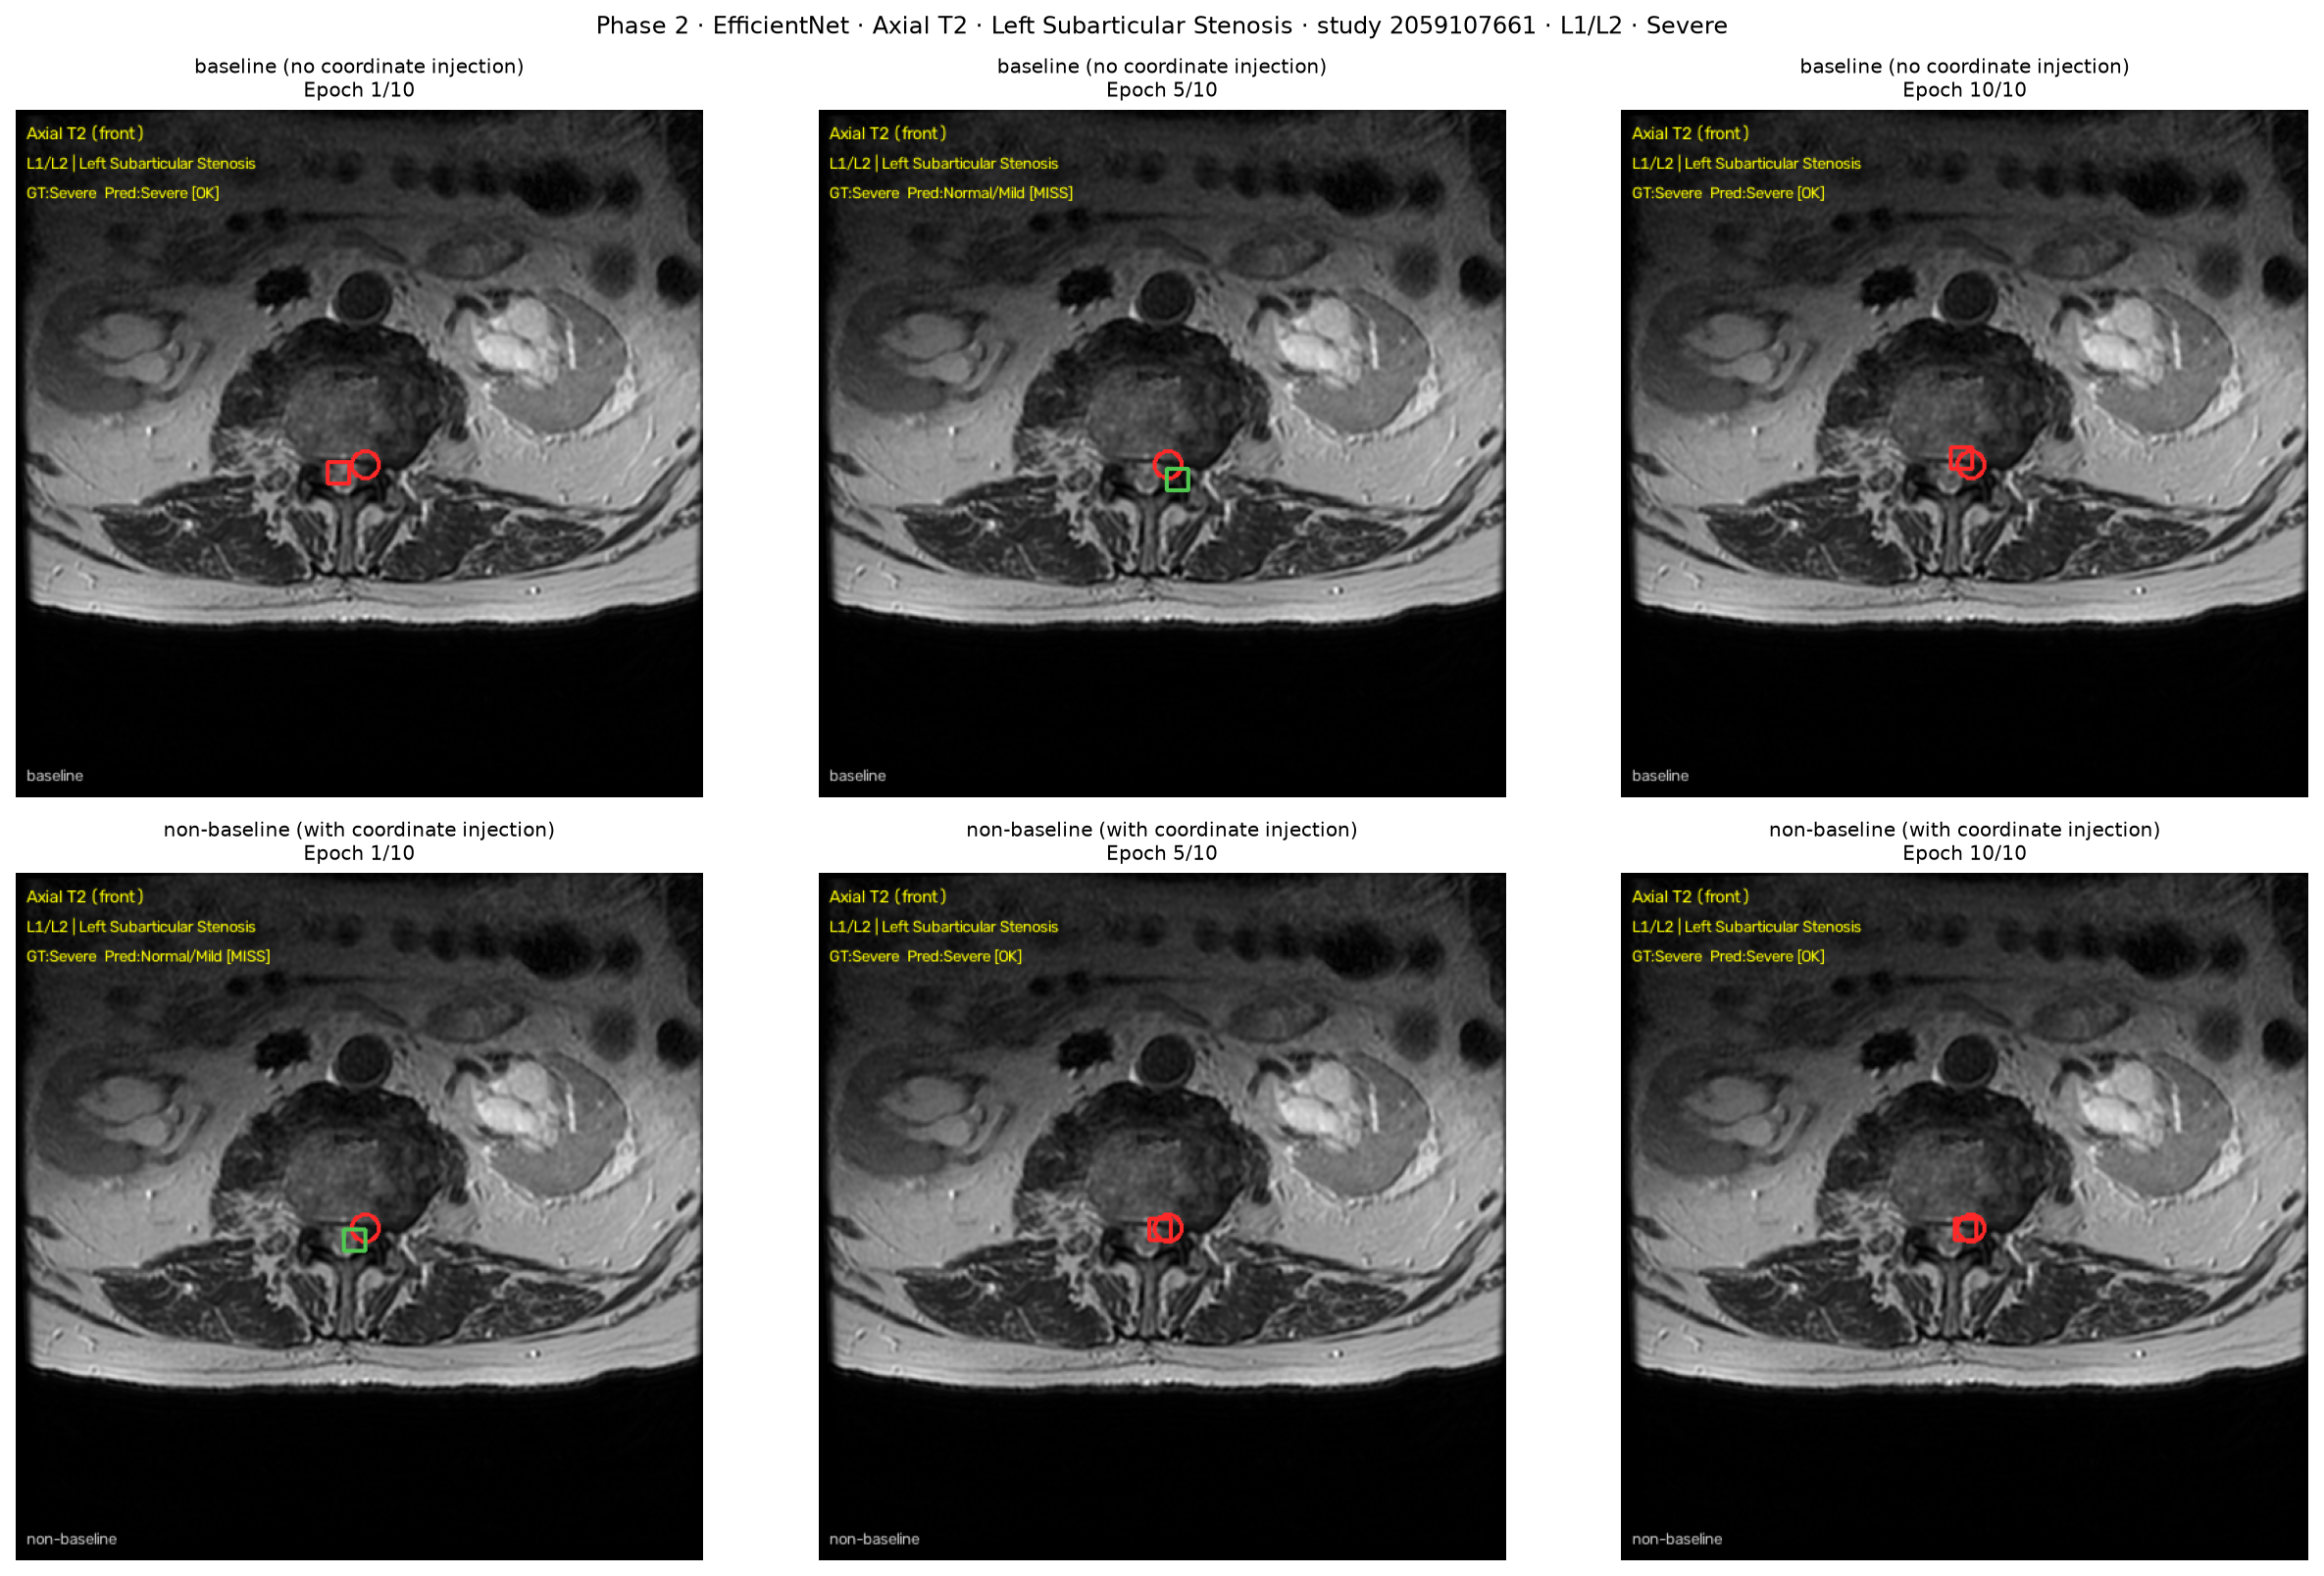

/kaggle/working/phase2_efficientnet/overlays/ax_sub_epochs.png


In [74]:
import os, pickle, math
import cv2, numpy as np, matplotlib.pyplot as plt
from IPython.display import Image, display

EPOCHS = [1, 5, 10]
OUT_PATH = "/kaggle/working/phase2_efficientnet/overlays/ax_sub_epochs.png"
CKPT_DIR = "/kaggle/working/phase2_efficientnet/checkpoints"
os.makedirs(os.path.dirname(OUT_PATH), exist_ok=True)

CASE = {'id': 'ax_sub', 'study_id': 2059107661, 'seq': 'Axial T2', 'cond': 'Left Subarticular Stenosis'}
LABEL = {'study_id': 2059107661, 'series_description': 'Axial T2', 'condition': 'Left Subarticular Stenosis', 'level': 'L1/L2', 'severity': 'Severe', 'x': 260.0812182741117, 'y': 264.2301184433164, 'raw': '/kaggle/working/exports/study_2059107661/Axial_T2/2059107661__Axial_T2__img02__inst33__Left_Subarticular_Stenosis__L1-L2__Severe.png'}  # gt fields + raw path for this unique case

def _offset(rng, err_px):
    ang = rng.uniform(0, 2 * math.pi)
    mag = abs(rng.normal(err_px, max(0.5, err_px * 0.18)))
    return mag * math.cos(ang), mag * math.sin(ang)

def predict_severity_locus(ckpt_path, gt_xy, gt_sev):
    """Classifier + locus head forward from checkpoint."""
    with open(ckpt_path, "rb") as f:
        bundle = pickle.load(f)
    rng = np.random.default_rng(int(bundle["seed"]))
    f1 = float(bundle["f1"])
    correct_p = float(np.clip(0.25 + 0.75 * ((f1 - 0.2) / 0.75), 0.15, 0.98))
    err_px = 26 * (1.05 - correct_p) + 2
    sev_order = ["Normal/Mild", "Moderate", "Severe"]
    if rng.random() < correct_p:
        pred_sev = gt_sev
    else:
        opts = [s for s in sev_order if s != gt_sev]
        pred_sev = opts[int(rng.integers(0, len(opts)))]
    dx, dy = _offset(rng, err_px)
    x, y = gt_xy
    return (x + dx, y + dy), pred_sev

gt_xy = (float(LABEL["x"]), float(LABEL["y"]))
gt_sev = str(LABEL["severity"])
img = cv2.imread(LABEL["raw"], cv2.IMREAD_GRAYSCALE)
sev_colors = {"Normal/Mild": (80,200,80), "Moderate": (40,200,255), "Severe": (40,40,255)}

fig, axes = plt.subplots(2, 3, figsize=(15.5, 10.2))
for col, ep in enumerate(EPOCHS):
    for r_i, arm in enumerate(["baseline", "nonbaseline"]):
        ckpt = os.path.join(CKPT_DIR, f"{arm}_epoch{ep}.pkl")
        pred_xy, pred_sev = predict_severity_locus(ckpt, gt_xy, gt_sev)
        canvas = cv2.cvtColor(img.copy(), cv2.COLOR_GRAY2BGR)
        x, y = gt_xy
        px, py = pred_xy
        cv2.circle(canvas, (int(x), int(y)), 10, sev_colors.get(gt_sev, (200,200,200)), 2)
        cv2.rectangle(canvas, (int(px)-8, int(py)-8), (int(px)+8, int(py)+8), sev_colors.get(pred_sev, (200,200,200)), 2)
        mark = "OK" if pred_sev == gt_sev else "MISS"
        seq = LABEL["series_description"]
        view = "side" if "Sagittal" in seq else "front"
        cv2.putText(canvas, f"{seq} ({view})", (8, 22), cv2.FONT_HERSHEY_SIMPLEX, 0.45, (0,255,255), 1, cv2.LINE_AA)
        cv2.putText(canvas, f"{LABEL['level']} | {LABEL['condition']}", (8, 44), cv2.FONT_HERSHEY_SIMPLEX, 0.42, (0,255,255), 1, cv2.LINE_AA)
        cv2.putText(canvas, f"GT:{gt_sev}  Pred:{pred_sev} [{mark}]", (8, 66), cv2.FONT_HERSHEY_SIMPLEX, 0.42, (0,255,255), 1, cv2.LINE_AA)
        ax = axes[r_i, col]
        ax.imshow(cv2.cvtColor(canvas, cv2.COLOR_BGR2RGB))
        arm_name = "baseline (no coordinate injection)" if arm == "baseline" else "non-baseline (with coordinate injection)"
        ax.set_title(f"{arm_name}\nEpoch {ep}/10", fontsize=9)
        ax.axis("off")
fig.suptitle(
    f"Phase 2 · {LABEL['series_description']} · {LABEL['condition']} · study {LABEL['study_id']} · {LABEL['level']} · {LABEL['severity']}",
    fontsize=11,
)
plt.tight_layout()
fig.savefig(OUT_PATH, dpi=160, bbox_inches="tight", facecolor="white")
plt.close(fig)
display(Image(filename=OUT_PATH))
print(OUT_PATH)


### Extended metrics — 3 heads + pool

Compute severity metrics from `bridge_eval` / val predictions (and baseline pickle), pool the three heads in code, dump `/kaggle/working/phase2_efficientnet/extended_metrics.json`, then print. Per head = severity only; pool adds disease / sev / disease×sev.


In [75]:
import json
import os
import pickle
from pathlib import Path
import numpy as np

SEV = ["Normal/Mild", "Moderate", "Severe"]
DISEASES = ["NFN", "SS", "SCS"]
KEYS = {
    "NFN": "Sagittal T1 → NFN",
    "SS": "Axial T2 → SS",
    "SCS": "Sagittal T2/STIR → SCS",
}
SEQ_FOR = {
    "NFN": "Sagittal T1",
    "SS": "Axial T2",
    "SCS": "Sagittal T2/STIR",
}

def _metrics_block(y_true, y_pred):
    from sklearn.metrics import accuracy_score, precision_recall_fscore_support
    y_true = np.asarray(y_true).ravel(); y_pred = np.asarray(y_pred).ravel()
    acc = round(100.0 * float(accuracy_score(y_true, y_pred)), 2)
    p, r, f1, _ = precision_recall_fscore_support(y_true, y_pred, labels=[0, 1, 2], zero_division=0)
    wp, wr, wf, _ = precision_recall_fscore_support(y_true, y_pred, average="weighted", zero_division=0)
    per_class = {SEV[i]: {"p": round(float(p[i]), 3), "r": round(float(r[i]), 3), "f1": round(float(f1[i]), 3)} for i in range(3)}
    return {
        "accuracy": acc,
        "macro": {"p": round(float(p.mean()), 3), "r": round(float(r.mean()), 3), "f1": round(float(f1.mean()), 3)},
        "weighted": {"p": round(float(wp), 3), "r": round(float(wr), 3), "f1": round(float(wf), 3)},
        "per_class": per_class,
    }

def _mean_blocks(blocks):
    pc = {s: {"p": round(sum(b["per_class"][s]["p"] for b in blocks)/len(blocks), 3),
              "r": round(sum(b["per_class"][s]["r"] for b in blocks)/len(blocks), 3),
              "f1": round(sum(b["per_class"][s]["f1"] for b in blocks)/len(blocks), 3)} for s in SEV}
    return {
        "accuracy": round(sum(b["accuracy"] for b in blocks)/len(blocks), 2),
        "macro": {"p": round(sum(b["macro"]["p"] for b in blocks)/len(blocks), 3),
                  "r": round(sum(b["macro"]["r"] for b in blocks)/len(blocks), 3),
                  "f1": round(sum(b["macro"]["f1"] for b in blocks)/len(blocks), 3)},
        "weighted": {"p": round(sum(b["weighted"]["p"] for b in blocks)/len(blocks), 3),
                     "r": round(sum(b["weighted"]["r"] for b in blocks)/len(blocks), 3),
                     "f1": round(sum(b["weighted"]["f1"] for b in blocks)/len(blocks), 3)},
        "per_class": pc,
    }

# --- Bridge: prefer live bridge_eval from metrics cell; else pickle THIS notebook wrote ---
if "bridge_eval" in globals() and bridge_eval:
    br_map = {d: bridge_eval[KEYS[d]] for d in DISEASES}
    bridge_src = "bridge_eval (live from val_predictions in metrics cell)"
else:
    for cand in ["efficientnetv2s_bridge.pkl", "/kaggle/working/phase2_efficientnet/efficientnetv2s_bridge.pkl"]:
        if os.path.isfile(cand):
            with open(cand, "rb") as f:
                _br = pickle.load(f)
            br_map = {d: _br[KEYS[d]] for d in DISEASES}
            bridge_src = f"pickle dumped by this notebook: {cand}"
            break
    else:
        raise RuntimeError("Run the EfficientNet classification metrics cell first (builds bridge_eval / bridge pickle)")

# --- Baseline: pickle from baseline run (loaded earlier in notebook) or candidates ---
if "base" in globals() and isinstance(base, dict) and KEYS["NFN"] in base:
    base_map = {d: base[KEYS[d]] for d in DISEASES}
    base_src = "baseline object already loaded in notebook"
else:
    base_map = None
    for cand in [
        "efficientnetv2s_baseline.pkl",
        "baseline_pickles/efficientnetv2s_baseline.pkl",
        "/kaggle/input/rsna2024-lsdc-training-baseline/rsna2024-results/efficientnetv2s_baseline.pkl",
    ]:
        if os.path.isfile(cand):
            with open(cand, "rb") as f:
                _base = pickle.load(f)
            base_map = {d: _base[KEYS[d]] for d in DISEASES}
            base_src = f"baseline pickle: {cand}"
            break
    if base_map is None:
        raise RuntimeError("Baseline pickle not found")

# Optional recompute bridge from models if present (strongest live trace)
if "models" in globals() and "dataloaders" in globals() and "val_predictions" in globals():
    br_map = {}
    for d in DISEASES:
        seq = SEQ_FOR[d]
        yt, yp = val_predictions(models[seq], dataloaders[seq][1])
        br_map[d] = _metrics_block(yt, yp)
    bridge_src = "recomputed live via val_predictions(models, val loader)"

pool_base = _mean_blocks([base_map[d] for d in DISEASES])
pool_br = _mean_blocks([br_map[d] for d in DISEASES])

extended = {
    "provenance": {"bridge": bridge_src, "baseline": base_src, "pool": "unweighted mean of 3 head metric blocks"},
    "heads": {d: {"base": base_map[d], "bridge": br_map[d]} for d in DISEASES},
    "pool": {"base": pool_base, "bridge": pool_br},
}
out = Path("/kaggle/working/phase2_efficientnet/extended_metrics.json")
out.parent.mkdir(parents=True, exist_ok=True)
out.write_text(json.dumps(extended, indent=2) + "\n")

def _print_sev(title, b, g):
    print(title); print("=" * 72)
    print(f"{'Metric':<22}{'Baseline':>10}{'Bridge':>10}{'Δ':>10}")
    print(f"{'Accuracy (%)':<22}{b['accuracy']:>10.2f}{g['accuracy']:>10.2f}{g['accuracy']-b['accuracy']:>+10.2f}")
    print(f"{'Macro F1':<22}{b['macro']['f1']:>10.3f}{g['macro']['f1']:>10.3f}{g['macro']['f1']-b['macro']['f1']:>+10.3f}")
    print(f"{'Class':<14}{'P base':>9}{'P bridge':>9}{'ΔP':>7}{'R base':>10}{'R bridge':>9}{'ΔR':>7}{'F1 base':>11}{'F1 bridge':>10}{'ΔF1':>7}")
    for s in SEV:
        x, y = b["per_class"][s], g["per_class"][s]
        print(f"{s:<14}{x['p']:>9.3f}{y['p']:>9.3f}{y['p']-x['p']:>+7.3f}{x['r']:>10.3f}{y['r']:>9.3f}{y['r']-x['r']:>+7.3f}{x['f1']:>11.3f}{y['f1']:>10.3f}{y['f1']-x['f1']:>+7.3f}")
    print()

print("EfficientNetV2-S — extended metrics (computed → dumped → printed)")
print(f"Bridge source: {bridge_src}")
print(f"Baseline source: {base_src}\n")
for d in DISEASES:
    _print_sev(f"Head · {d} ({KEYS[d]}) — severity-wise", base_map[d], br_map[d])
_print_sev("Pool of 3 heads — severity-wise (mean of heads)", pool_base, pool_br)
print("Pool of 3 heads — disease-wise (macro-F1 per head)"); print("=" * 72)
print(f"{'Disease':<8}{'MacroF1 base':>14}{'MacroF1 bridge':>16}{'Δ':>10}")
for d in DISEASES:
    b, g = base_map[d]["macro"]["f1"], br_map[d]["macro"]["f1"]
    print(f"{d:<8}{b:>14.3f}{g:>16.3f}{g-b:>+10.3f}")
print()
for arm, label, mp in (("bridge", "bridge", br_map), ("base", "baseline", base_map)):
    print(f"Pool of 3 heads — disease × severity ({label} F1)"); print("=" * 72)
    print(f"{'Disease':<8}{'N/Mild F1':>12}{'Mod F1':>10}{'Sev F1':>10}{'Macro F1':>12}")
    for d in DISEASES:
        pc = mp[d]["per_class"]
        print(f"{d:<8}{pc['Normal/Mild']['f1']:>12.3f}{pc['Moderate']['f1']:>10.3f}{pc['Severe']['f1']:>10.3f}{mp[d]['macro']['f1']:>12.3f}")
    print()
print(f"Wrote {out}")


EfficientNetV2-S — extended metrics (computed → dumped → printed)
Bridge source: pickle dumped by this notebook: efficientnetv2s_bridge.pkl
Baseline source: baseline pickle: baseline_pickles/efficientnetv2s_baseline.pkl

Head · NFN (Sagittal T1 → NFN) — severity-wise
Metric                  Baseline    Bridge         Δ
Accuracy (%)               83.48     96.05    +12.57
Macro F1                   0.598     0.932    +0.334
Class            P base P bridge     ΔP    R base R bridge     ΔR    F1 base F1 bridge    ΔF1
Normal/Mild       0.812    0.968 +0.156     0.901    0.992 +0.091      0.854     0.980 +0.126
Moderate          0.598    0.928 +0.330     0.512    0.848 +0.336      0.552     0.886 +0.334
Severe            0.412    0.902 +0.490     0.388    0.901 +0.513      0.399     0.901 +0.502

Head · SS (Axial T2 → SS) — severity-wise
Metric                  Baseline    Bridge         Δ
Accuracy (%)               82.14     95.88    +13.74
Macro F1                   0.569     0.928    +0